In [4]:
# Nguồn 1: https://www.kaggle.com/datasets/mashlyn/online-retail-ii-uci
# Nguồn 2: https://www.kaggle.com/datasets/carrie1/ecommerce-data

# NOTEBOOK TỔNG — STAGE 1 → STAGE 2

Nguồn code: https://github.com/chikg45/Project_Team_9 — commit `1c72c3fee46d4e231df2a4692686d4f0d3e44280`.

**Cách chạy:** giải nén gói đầy đủ, mở notebook này tại thư mục gốc, chọn Python rồi **Restart Kernel → Run All**. Cài thư viện một lần trong terminal: `python -m pip install -r requirements.txt`. Không cần chạy 5 notebook cũ trước.

Thứ tự: Data_EDA → PCA → KMeans → Regression → Classification → UI và tổng kết. Giữ toàn bộ cell nguồn, ghi xuất xứ trong metadata; phần bổ sung được ghi rõ. Notebook tổng không đồng nghĩa với chỉ cần một file: hai CSV gốc nằm trong ZIP kèm theo và giao diện Streamlit cần chạy bằng lệnh riêng.

Các câu mô tả việc chạy riêng/tách notebook trong nội dung gốc là ghi chú cũ được giữ nguyên; hướng dẫn chạy tổng ở đây được ưu tiên. Các con số trong markdown gốc được đối chiếu với lần chạy ở cuối notebook.

In [5]:
from pathlib import Path
import os
# Hỗ trợ mở từ gốc dự án hoặc thư mục notebooks.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'Data').is_dir() and (p / 'notebooks').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Hãy giải nén gói đầy đủ và mở notebook từ thư mục dự án.')
for folder in ['Data/data_goc', 'Data/csdl', 'Data/simulated', 'Data/processed', 'models', 'app']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
# Giới hạn thread để tránh quá tải CPU; không đổi tham số mô hình.
os.environ['OMP_NUM_THREADS'] = '2'
os.environ['OPENBLAS_NUM_THREADS'] = '2'


# STAGE 1 — Data_EDA

Các cell tiếp theo lấy từ `Data_EDA.ipynb`.

In [6]:
# Nguồn 1: https://www.kaggle.com/datasets/mashlyn/online-retail-ii-uci
# Nguồn 2: https://www.kaggle.com/datasets/carrie1/ecommerce-data



# CHUẨN BỊ VÀ PHÂN TÍCH DỮ LIỆU KHÁCH HÀNG THƯƠNG MẠI ĐIỆN TỬ


**Mục tiêu dữ liệu:** mỗi dòng cuối cùng là một khách hàng, phục vụ phân nhóm khách hàng và dự đoán giá trị mua / có mua lại ở giai đoạn sau. 

**Nguồn:** hai CSV trong `data_goc`, tải từ hai bộ Kaggle Online Retail II và Online Retail. Hai bộ cùng nhà bán lẻ, cùng nguồn gốc UCI, không phải hai cửa hàng độc lập. Dữ liệu có thời gian chồng lấn nên chia giai đoạn trước khi concat. Giá trị tiền dùng GBP.



In [7]:
from pathlib import Path

# Tìm thư mục dự án khi mở từ thư mục gốc hoặc notebooks.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'Data').is_dir() and (p / 'notebooks').is_dir())
import os
from zipfile import ZipFile

os.chdir(ROOT / 'Data')
Path('data_goc').mkdir(exist_ok=True)
Path('csdl').mkdir(exist_ok=True)
Path('simulated').mkdir(exist_ok=True)
Path('processed').mkdir(exist_ok=True)
if not Path('data_goc/online_retail_II.csv').exists() or not Path('data_goc/online_retail.csv').exists():
    with ZipFile(ROOT / 'data_goc' / 'raw_data.zip') as tep:
        tep.extractall('data_goc')


## Step 1: Static Data Acquisition — Đọc dữ liệu tĩnh

Giữ nguyên phần 1 và phần 2 đã được chỉnh sửa bên dưới. Phần chuẩn hóa ban đầu ở phần 2 được giữ tại vị trí này theo yêu cầu của người làm bài.


## 1. Nạp thư viện và đọc CSV gốc


- Encoding để đọc ký tự đặc biệt
- Đổi các mã thành kiểu chuỗi bởi vì mã có thể chứa số 0 đằng trước hoặc có ký tự.

In [8]:
# Nguồn 1: https://www.kaggle.com/datasets/mashlyn/online-retail-ii-uci
# Nguồn 2: https://www.kaggle.com/datasets/carrie1/ecommerce-data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

cu = pd.read_csv('data_goc/online_retail_II.csv', encoding='ISO-8859-1',
                 dtype={'Invoice': 'string', 'StockCode': 'string'})
moi = pd.read_csv('data_goc/online_retail.csv', encoding='ISO-8859-1',
                  dtype={'InvoiceNo': 'string', 'StockCode': 'string'})
print('Online Retail II:', cu.shape, '| Online Retail:', moi.shape)
display(cu.head(3))
display(moi.head(3))


Online Retail II: (1067371, 8) | Online Retail: (541909, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom


## 2. Kiểm tra và chuẩn hóa trước concat
Đổi tên Invoice/Price/Customer ID của bộ cũ cho giống bộ mới. Đọc ngày theo đúng định dạng từng file; chuẩn hóa mã khách về chuỗi, giá/số lượng về số. Không thay giá trị thiếu của mã khách bằng một mã giả.

In [9]:
cu = cu.rename(columns={'Invoice': 'InvoiceNo', 'Price': 'UnitPrice', 'Customer ID': 'CustomerID'})
print('Tên cột nguồn 1:', cu.columns.tolist())
print('Tên cột nguồn 2:', moi.columns.tolist())
moi = moi[cu.columns].copy()
cu['InvoiceDate'] = pd.to_datetime(cu['InvoiceDate'], format='%Y-%m-%d %H:%M:%S')
moi['InvoiceDate'] = pd.to_datetime(moi['InvoiceDate'], format='%m/%d/%Y %H:%M')
display(cu)
display(moi)


display(cu.dtypes)
display(moi.dtypes)



Tên cột nguồn 1: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
Tên cột nguồn 2: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
...,...,...,...,...,...,...,...,...
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


InvoiceNo      string[python]
StockCode      string[python]
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

InvoiceNo      string[python]
StockCode      string[python]
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

## Step 2: Dynamic Data Generation — Sinh dữ liệu động

Lấy danh sách khách đủ điều kiện từ từng nguồn để chọn 1.000 khách như phạm vi ban đầu, chưa concat hoặc merge bảng giao dịch. Sinh kênh liên hệ giả định bằng NumPy (seed=42), ba kênh xác suất bằng nhau và 4% thiếu theo giả định. Xuất CSV mô phỏng. Đây không phải dữ liệu khảo sát và không dùng làm đặc trưng hành vi thật.


In [10]:
bat_dau = pd.Timestamp('2010-03-01')
moc_du_doan = pd.Timestamp('2011-09-01')
ket_thuc = moc_du_doan + pd.Timedelta(days=90)
moc_nguon = pd.Timestamp('2010-12-01')

# Lấy mã khách từ hai giai đoạn không chồng lấn, chưa gộp bảng giao dịch.
danh_sach_khach = []
for bang, ngay_dau, ngay_cuoi in [
    (cu, bat_dau, moc_nguon),
    (moi, moc_nguon, moc_du_doan)
]:
    dieu_kien = (
        bang['CustomerID'].notna()
        & ~bang['InvoiceNo'].str.upper().str.startswith('C')
        & (bang['Quantity'] > 0)
        & (bang['UnitPrice'] > 0)
        & (bang['InvoiceDate'] >= ngay_dau)
        & (bang['InvoiceDate'] < ngay_cuoi)
    )
    ma_khach = bang.loc[dieu_kien, 'CustomerID'].astype('Int64').astype('string')
    danh_sach_khach.extend(ma_khach.tolist())
khach_truoc = pd.Series(danh_sach_khach, dtype='string').drop_duplicates().sort_values()
khach_chon = khach_truoc.sample(n=1000, random_state=42)

mo_phong = pd.DataFrame({'CustomerID': sorted(khach_chon)})
rng = np.random.default_rng(42)
mo_phong['Kenh_lien_he_mo_phong'] = rng.choice(['Email', 'SMS', 'Phone'], len(mo_phong))
mo_phong.loc[rng.random(len(mo_phong)) < 0.04, 'Kenh_lien_he_mo_phong'] = None
mo_phong.to_csv('simulated/du_lieu_mo_phong.csv', index=False, encoding='utf-8-sig')
print('Khách đủ điều kiện:', len(khach_truoc))
print('Số khách mô phỏng:', len(mo_phong))
display(mo_phong.head())


Khách đủ điều kiện: 5015
Số khách mô phỏng: 1000


,CustomerID,Kenh_lien_he_mo_phong
0,12354,Email
1,12358,Phone
2,12363,SMS
3,12365,SMS
4,12370,SMS


## Step 3: Data Integration — Concat và Merge

Phần 2 đã đổi tên và sắp xếp cột, chuyển ngày giờ. Tiếp tục thống nhất kiểu mã khách và số liệu để ghép đúng với bảng mô phỏng.


In [11]:
# Chuẩn hóa cùng kiểu mã khách trước khi lọc mẫu và ghép.
for bang in [cu, moi]:
    bang['CustomerID'] = pd.to_numeric(bang['CustomerID']).astype('Int64').astype('string')
    bang['Quantity'] = pd.to_numeric(bang['Quantity'])
    bang['UnitPrice'] = pd.to_numeric(bang['UnitPrice'])
    for cot in ['Description', 'Country']:
        bang[cot] = bang[cot].astype('string').str.strip().replace('', pd.NA)


### 3.1. Gộp dọc hai giai đoạn không chồng lấn
`concat` thêm dòng cho cùng loại đối tượng: dòng hóa đơn. Nhãn Source ghi nơi tải, không phải cửa hàng. Mã CustomerID có cùng ý nghĩa vì cùng nhà bán lẻ. Không thêm Source vào mã khách để chia một khách thành hai người.

In [12]:
moc_nguon = pd.Timestamp('2010-12-01')
phan_cu = cu[cu['InvoiceDate'] < moc_nguon].copy()
phan_moi = moi[moi['InvoiceDate'] >= moc_nguon].copy()
phan_cu['Source'] = 'OnlineRetailII'
phan_moi['Source'] = 'OnlineRetail'
df = pd.concat([phan_cu, phan_moi], ignore_index=True)
display(df.groupby('Source')['InvoiceDate'].agg(['count', 'min', 'max']))
print('Số dòng trùng đủ cột (chưa xóa):', df.duplicated().sum())


,count,min,max
Source,,,
OnlineRetail,541909,2010-12-01 08:26:00,2011-12-09 12:50:00
OnlineRetailII,502938,2009-12-01 07:45:00,2010-11-30 19:35:00


Số dòng trùng đủ cột (chưa xóa): 11812


### 3.2. Giữ giao dịch thuộc phạm vi và mẫu khách đã chọn
Chỉ dùng hóa đơn không bắt đầu bằng C, Quantity>0, UnitPrice>0, có mã khách để đo **giá trị mua dương**, không phải doanh thu ròng đã trừ hoàn trả. In riêng số dòng nằm ngoài phạm vi; không điền mã khách thiếu bằng mode/Unknown vì sẽ ghép nhầm nhiều người.

Mô tả sản phẩm có thể thiếu nhưng không cần cho RFM, không xóa vì thiếu mô tả. Các dòng trùng đủ cột được giữ vì không có mã dòng gốc để chứng minh là lỗi; giá trị mua là tổng dòng theo nguồn, chưa phải số tiền ngân hàng đã xác minh.

Chọn 1.000 mã khách bằng `sample(random_state=42)` từ kỳ quan sát, rồi giữ toàn bộ giao dịch hợp lệ của họ trong hai kỳ. Không đọc nhãn để chọn khách.

In [13]:
print('Dòng thiếu mã khách:', df['CustomerID'].isna().sum())
print('Dòng hủy C:', df['InvoiceNo'].str.upper().str.startswith('C').sum())
print('Dòng số lượng không dương:', (df['Quantity'] <= 0).sum())
print('Dòng giá không dương:', (df['UnitPrice'] <= 0).sum())
hop_le = (df['CustomerID'].notna() & ~df['InvoiceNo'].str.upper().str.startswith('C')
          & (df['Quantity'] > 0) & (df['UnitPrice'] > 0))
mua = df[hop_le & (df['InvoiceDate'] >= bat_dau) & (df['InvoiceDate'] < ket_thuc)].copy()
mua = mua[mua['CustomerID'].isin(khach_chon)].copy()
print('Khách đủ điều kiện:', len(khach_truoc), '| Khách được chọn:', len(khach_chon))
print('Dòng hợp lệ được dùng:', len(mua))
display(mua.groupby('Source').size())


Dòng thiếu mã khách: 235287
Dòng hủy C: 19165
Dòng số lượng không dương: 22557
Dòng giá không dương: 6029
Khách đủ điều kiện: 5015 | Khách được chọn: 1000
Dòng hợp lệ được dùng: 122669


Source
OnlineRetail      63218
OnlineRetailII    59451
dtype: int64

### 3.3. Tạo bảng hóa đơn tĩnh
Gom các dòng hàng thành hóa đơn bằng groupby: cộng giá trị Quantity×UnitPrice và số lượng; đếm mã hàng trong mỗi hóa đơn. Đây là đổi đơn vị từ dòng hàng sang hóa đơn để lưu gọn, không phải bịa dữ liệu.

Kiểm tra một InvoiceNo không thuộc nhiều khách; Country lấy ở dòng cuối của hóa đơn. Thời gian là ngày giờ theo nguồn, không tự gán UTC khi tài liệu không xác định múi giờ.

In [14]:
mua['LineAmountGBP'] = mua['Quantity'] * mua['UnitPrice']
mua = mua.sort_values('InvoiceDate')
hoa_don = mua.groupby('InvoiceNo', as_index=False).agg(
    CustomerID=('CustomerID', 'first'), InvoiceDate=('InvoiceDate', 'min'),
    Country=('Country', 'last'), Source=('Source', 'first'),
    AmountGBP=('LineAmountGBP', 'sum'), Units=('Quantity', 'sum'),
    ProductsInInvoice=('StockCode', 'nunique'))
hoa_don['RowID'] = np.arange(len(hoa_don))
print('Bảng tĩnh:', hoa_don.shape)
display(hoa_don.head())


Bảng tĩnh: (5847, 9)


,InvoiceNo,CustomerID,InvoiceDate,Country,Source,AmountGBP,Units,ProductsInInvoice,RowID
0,499511,16717,2010-03-01 08:55:00,United Kingdom,OnlineRetailII,347.50,121,14,0
1,499576,13948,2010-03-01 12:16:00,United Kingdom,OnlineRetailII,106.66,78,6,1
2,499624,17593,2010-03-01 13:10:00,United Kingdom,OnlineRetailII,669.71,365,26,2
3,499630,16273,2010-03-01 13:24:00,United Kingdom,OnlineRetailII,76.50,6,1,3
4,499637,12989,2010-03-01 13:45:00,United Kingdom,OnlineRetailII,313.10,106,3,4


### 3.4. Merge với dữ liệu động

Dùng **left join** theo CustomerID để giữ mọi hóa đơn của mẫu khách. Một khách có thể có nhiều hóa đơn, bảng mô phỏng có một dòng/khách nên dùng `many_to_one`. Dữ liệu mô phỏng đã được tạo ở Step 2, không sinh lại.


In [15]:
n_truoc = len(hoa_don)
hoa_don = pd.merge(hoa_don, mo_phong, on='CustomerID', how='left', validate='many_to_one')
print('Số hóa đơn trước/sau merge:', n_truoc, len(hoa_don))
display(hoa_don.head())


Số hóa đơn trước/sau merge: 5847 5847


,InvoiceNo,CustomerID,InvoiceDate,Country,Source,AmountGBP,Units,ProductsInInvoice,RowID,Kenh_lien_he_mo_phong
0,499511,16717,2010-03-01 08:55:00,United Kingdom,OnlineRetailII,347.50,121,14,0,Email
1,499576,13948,2010-03-01 12:16:00,United Kingdom,OnlineRetailII,106.66,78,6,1,Email
2,499624,17593,2010-03-01 13:10:00,United Kingdom,OnlineRetailII,669.71,365,26,2,Email
3,499630,16273,2010-03-01 13:24:00,United Kingdom,OnlineRetailII,76.50,6,1,3,Phone
4,499637,12989,2010-03-01 13:45:00,United Kingdom,OnlineRetailII,313.10,106,3,4,Email


## Step 4: Modern Data Storage — SQLite và Qdrant
Đề yêu cầu hai loại CSDL. SQLite là quan hệ; Qdrant là vector, chạy local không cần tài khoản. Lưu toàn bộ hóa đơn vào payload Qdrant; vector chỉ gồm AmountGBP và Units để minh họa lưu trữ, không dùng khoảng cách này kết luận tương đồng. Không huấn luyện AI ở đây.

Chạy lại sẽ thay bảng/collection của bài tại `csdl`.

In [16]:
from qdrant_client import QdrantClient, models

de_luu = hoa_don.copy()
de_luu['InvoiceDate'] = de_luu['InvoiceDate'].dt.strftime('%Y-%m-%d %H:%M:%S')
de_luu = de_luu.astype(object).where(pd.notna(de_luu), None)
with sqlite3.connect('csdl/retail.sqlite') as conn:
    de_luu.to_sql('hoa_don', conn, if_exists='replace', index=False)

q = QdrantClient(path='csdl/qdrant')
if q.collection_exists('hoa_don'):
    q.delete_collection('hoa_don')
q.create_collection('hoa_don', vectors_config=models.VectorParams(size=2, distance=models.Distance.EUCLID))
points = []
for row in de_luu.to_dict('records'):
    points.append(models.PointStruct(id=int(row['RowID']),
        vector=[float(row['AmountGBP']), float(row['Units'])], payload=row))
q.upsert('hoa_don', points=points)
q.close()
print('Đã lưu', len(de_luu), 'hóa đơn vào cả hai CSDL.')


Đã lưu 5847 hóa đơn vào cả hai CSDL.


## Advanced Data Cleaning & Exploratory Data Analysis (EDA)


### Đọc lại dữ liệu từ hai CSDL
Mở kết nối mới; Qdrant đọc từng trang đến hết. So sánh toàn bộ bảng hai CSDL, không chỉ số dòng. Từ đây dữ liệu phân tích lấy từ SQLite.

In [17]:
with sqlite3.connect('csdl/retail.sqlite') as conn:
    tu_sql = pd.read_sql_query('SELECT * FROM hoa_don ORDER BY RowID', conn)
q = QdrantClient(path='csdl/qdrant')
rows = []
offset = None
while True:
    page, offset = q.scroll('hoa_don', limit=1000, offset=offset, with_payload=True, with_vectors=False)
    for point in page:
        rows.append(point.payload)
    if offset is None:
        break
q.close()
tu_q = pd.DataFrame(rows).sort_values('RowID').reset_index(drop=True)
print('Số dòng SQLite:', len(tu_sql))
print('Số dòng Qdrant:', len(tu_q))
print('Nội dung hai bảng giống nhau:', tu_sql.equals(tu_q[tu_sql.columns]))
hoa_don = tu_sql.copy()
hoa_don['InvoiceDate'] = pd.to_datetime(hoa_don['InvoiceDate'])
print('Đã đọc lại và đối chiếu đủ:', len(hoa_don), 'hóa đơn.')


Số dòng SQLite: 5847
Số dòng Qdrant: 5847
Nội dung hai bảng giống nhau: True
Đã đọc lại và đối chiếu đủ: 5847 hóa đơn.


### 1. Handling Missing Values — Xử lý dữ liệu thiếu

Tính số lượng và phần trăm thiếu của từng cột sau khi đọc từ CSDL. Không tự sinh số tiền, mã khách hoặc ngày giao dịch để lấp chỗ trống. Dòng gốc thiếu mã khách được thống kê ở mục 3.2 và nằm ngoài phạm vi phân tích theo khách, vì không xác định được người mua.

Hàm `lam_sach` điền `Unknown` cho các cột phân loại còn thiếu. Các cột số ở bảng hóa đơn hợp lệ được kiểm tra không thiếu; vì vậy không cần điền median vào chúng. Không dùng ffill/bfill qua các hóa đơn của các khách khác nhau vì có thể gán thông tin người này cho người khác.

Kênh liên hệ là mô phỏng, bao gồm tỷ lệ thiếu giả định được ghi rõ ở Step 2; không xem đây là dữ liệu hành vi thật. So sánh bảng tần suất và tỷ lệ trước/sau, tách nhãn `Missing` trước xử lý và `Unknown` sau xử lý.


,So_thieu,Phan_tram
InvoiceNo,0,0.000000
CustomerID,0,0.000000
InvoiceDate,0,0.000000
Country,0,0.000000
Source,0,0.000000
AmountGBP,0,0.000000
Units,0,0.000000
ProductsInInvoice,0,0.000000
RowID,0,0.000000
Kenh_lien_he_mo_phong,205,3.506071


Số ô thiếu ở mã, ngày và số liệu giao dịch:
CustomerID           0
InvoiceDate          0
AmountGBP            0
Units                0
ProductsInInvoice    0
dtype: int64
Country


,So_luong_truoc,So_luong_sau,Ty_le_truoc,Ty_le_sau
Country,,,,
United Kingdom,5226,5226,89.379169,89.379169
Germany,280,280,4.788781,4.788781
France,139,139,2.377287,2.377287
Belgium,35,35,0.598598,0.598598
Sweden,28,28,0.478878,0.478878
Netherlands,15,15,0.256542,0.256542
Austria,15,15,0.256542,0.256542
Spain,13,13,0.222336,0.222336
Switzerland,11,11,0.188131,0.188131


Kenh_lien_he_mo_phong


,So_luong_truoc,So_luong_sau,Ty_le_truoc,Ty_le_sau
Kenh_lien_he_mo_phong,,,,
SMS,1930.0,1930.0,33.008380,33.008380
Email,1883.0,1883.0,32.204549,32.204549
Phone,1829.0,1829.0,31.280999,31.280999
Missing,205.0,0.0,3.506071,0.000000
Unknown,0.0,205.0,0.000000,3.506071


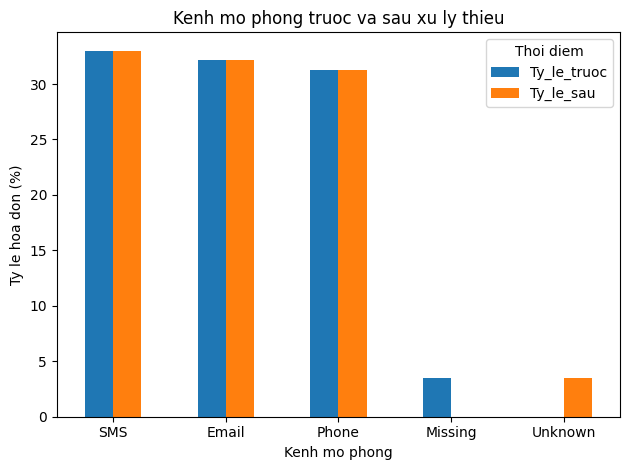

Tổng ô thiếu sau xử lý: 0


In [18]:
missing = pd.DataFrame({
    'So_thieu': hoa_don.isna().sum(),
    'Phan_tram': hoa_don.isna().mean() * 100
})
display(missing)
print('Số ô thiếu ở mã, ngày và số liệu giao dịch:')
print(hoa_don[['CustomerID', 'InvoiceDate', 'AmountGBP', 'Units', 'ProductsInInvoice']].isna().sum())

def lam_sach(bang):
    ket_qua = bang.copy()
    ket_qua['Country'] = ket_qua['Country'].fillna('Unknown')
    ket_qua['Kenh_lien_he_mo_phong'] = ket_qua['Kenh_lien_he_mo_phong'].fillna('Unknown')
    return ket_qua

truoc = hoa_don.copy()
hoa_don = lam_sach(hoa_don)
for cot in ['Country', 'Kenh_lien_he_mo_phong']:
    a = truoc[cot].fillna('Missing').value_counts()
    b = hoa_don[cot].value_counts()
    so_sanh = pd.concat([a, b], axis=1).fillna(0)
    so_sanh.columns = ['So_luong_truoc', 'So_luong_sau']
    so_sanh['Ty_le_truoc'] = so_sanh['So_luong_truoc'] / len(truoc) * 100
    so_sanh['Ty_le_sau'] = so_sanh['So_luong_sau'] / len(hoa_don) * 100
    print(cot)
    display(so_sanh)
so_sanh[['Ty_le_truoc', 'Ty_le_sau']].plot(kind='bar', rot=0)
plt.title('Kenh mo phong truoc va sau xu ly thieu')
plt.xlabel('Kenh mo phong'); plt.ylabel('Ty le hoa don (%)')
plt.legend(title='Thoi diem')
plt.tight_layout(); plt.show(); plt.close()
print('Tổng ô thiếu sau xử lý:', hoa_don.isna().sum().sum())


**Nhận xét — So what?** Nhóm `Missing` trước xử lý chuyển thành `Unknown` sau xử lý; các nhóm đã có thông tin giữ nguyên tần suất và tỷ lệ. Cách này giữ hóa đơn mà không đoán kênh liên hệ thật. Không có dữ liệu thiếu ở số tiền trong bảng đã chọn, nên không áp dụng điền số tùy ý. Kênh mô phỏng không dùng làm đặc trưng dự đoán hành vi khách hàng.


### Chuẩn bị bảng khách hàng cho EDA
Feature chỉ dùng hóa đơn trước mốc 01/09/2011. Recency là số ngày từ lần mua cuối đến mốc; Frequency là số hóa đơn; Monetary là tổng giá trị mua dương. Các biến khác được tính từ cùng kỳ quan sát.

Target hồi quy là tổng giá trị mua dương trong 90 ngày kế tiếp. Target phân loại bằng 1 khi có ít nhất một hóa đơn trong kỳ đó. Điền **0** cho khách không có hóa đơn kỳ sau vì đây là định nghĩa nhãn từ cửa sổ quan sát đầy đủ, không phải impute tiền bị thiếu.

Country là giá trị quan sát cuối trước mốc. Không dùng dữ liệu sau mốc để chọn quốc gia hoặc tạo feature.

In [19]:
truoc_moc = hoa_don[hoa_don['InvoiceDate'] < moc_du_doan].copy()
sau_moc = hoa_don[(hoa_don['InvoiceDate'] >= moc_du_doan) & (hoa_don['InvoiceDate'] < ket_thuc)].copy()
data = truoc_moc.groupby('CustomerID', as_index=False).agg(
    LastPurchase=('InvoiceDate', 'max'), FirstPurchase=('InvoiceDate', 'min'),
    Frequency=('InvoiceNo', 'nunique'), MonetaryGBP=('AmountGBP', 'sum'),
    TotalUnits=('Units', 'sum'), AvgProductsPerInvoice=('ProductsInInvoice', 'mean'),
    Country=('Country', 'last'), Kenh_lien_he_mo_phong=('Kenh_lien_he_mo_phong', 'first'))
data['RecencyDays'] = (moc_du_doan-data['LastPurchase']).dt.days
data['ObservedTenureDays'] = (moc_du_doan-data['FirstPurchase']).dt.days
data['AvgOrderValueGBP'] = data['MonetaryGBP']/data['Frequency']
nhan = sau_moc.groupby('CustomerID', as_index=False).agg(
    Chi_tieu_90_ngay_GBP=('AmountGBP', 'sum'), So_don_90_ngay=('InvoiceNo', 'nunique'))
data = data.merge(nhan, on='CustomerID', how='left', validate='one_to_one')
data[['Chi_tieu_90_ngay_GBP', 'So_don_90_ngay']] = data[['Chi_tieu_90_ngay_GBP', 'So_don_90_ngay']].fillna(0)
data['Mua_lai_90_ngay'] = (data['So_don_90_ngay'] > 0).astype(int)
data['RegionGroup'] = np.where(data['Country'] == 'United Kingdom', 'United Kingdom', 'Other countries')
data = data.drop(columns=['LastPurchase', 'FirstPurchase', 'So_don_90_ngay'])
print('Bảng khách:', data.shape)
display(data.head())
display(data['Mua_lai_90_ngay'].value_counts())


Bảng khách: (1000, 13)


,CustomerID,Frequency,MonetaryGBP,TotalUnits,AvgProductsPerInvoice,Country,Kenh_lien_he_mo_phong,RecencyDays,ObservedTenureDays,AvgOrderValueGBP,Chi_tieu_90_ngay_GBP,Mua_lai_90_ngay,RegionGroup
0,12354,1,1079.40,530,58.000000,Spain,Email,132,132,1079.400000,0.00,0,Other countries
1,12358,3,1774.04,622,17.333333,Austria,Phone,50,450,591.346667,0.00,0,Other countries
2,12363,2,552.00,408,11.500000,Unspecified,SMS,9,142,276.000000,0.00,0,Other countries
3,12365,2,641.38,174,11.000000,Cyprus,SMS,191,191,320.690000,0.00,0,Other countries
4,12370,5,3018.07,2053,29.600000,Cyprus,SMS,174,524,603.614000,739.28,1,Other countries


Mua_lai_90_ngay
0    557
1    443
Name: count, dtype: int64

### 2. Univariate Analysis — Thống kê đơn biến
Đủ mean, median, std, skewness, kurtosis; tần suất và tỷ lệ các biến phân loại. Kurtosis của pandas là excess kurtosis, phân phối chuẩn có giá trị 0.

In [20]:
cot_so = ['RecencyDays', 'Frequency', 'MonetaryGBP', 'TotalUnits',
          'AvgProductsPerInvoice', 'ObservedTenureDays', 'AvgOrderValueGBP', 'Chi_tieu_90_ngay_GBP']
tk = data[cot_so].describe().T
tk['median'] = data[cot_so].median()
tk['skewness'] = data[cot_so].skew()
tk['kurtosis'] = data[cot_so].kurt()
display(tk)
for cot in ['Country', 'RegionGroup', 'Mua_lai_90_ngay', 'Kenh_lien_he_mo_phong']:
    ts = data[cot].value_counts().to_frame('So_khach')
    ts['Phan_tram'] = ts['So_khach']/len(data)*100
    print(cot)
    display(ts)


,count,mean,std,min,25%,50%,75%,max,median,skewness,kurtosis
RecencyDays,1000.0,180.595000,146.667359,0.00,48.000000,142.000000,295.000000,548.00,142.000000,0.565423,-0.782462
Frequency,1000.0,4.881000,7.184320,1.00,1.000000,3.000000,5.250000,91.00,3.000000,5.304762,43.481112
MonetaryGBP,1000.0,1949.327965,4553.095061,3.75,306.435000,722.505000,1829.777500,84946.96,722.505000,9.594686,136.952411
TotalUnits,1000.0,1196.167000,4042.469043,1.00,161.500000,395.500000,1041.750000,88457.00,395.500000,14.295166,260.763119
AvgProductsPerInvoice,1000.0,20.756110,18.965401,1.00,9.000000,16.111111,25.500000,220.00,16.111111,3.293435,21.423643
ObservedTenureDays,1000.0,368.812000,149.452175,1.00,289.750000,394.000000,503.000000,548.00,394.000000,-0.708952,-0.458022
AvgOrderValueGBP,1000.0,365.695925,514.416646,3.75,173.956667,276.453750,408.373333,13305.50,276.453750,16.670154,402.746802
Chi_tieu_90_ngay_GBP,1000.0,422.265840,1058.002243,0.00,0.000000,0.000000,474.962500,16074.50,0.000000,7.046750,73.724342


Country


,So_khach,Phan_tram
Country,,
United Kingdom,902,90.2
Germany,24,2.4
France,18,1.8
Spain,7,0.7
Netherlands,6,0.6
Belgium,5,0.5
Sweden,5,0.5
Austria,4,0.4
Switzerland,3,0.3


RegionGroup


,So_khach,Phan_tram
RegionGroup,,
United Kingdom,902,90.2
Other countries,98,9.8


Mua_lai_90_ngay


,So_khach,Phan_tram
Mua_lai_90_ngay,,
0,557,55.7
1,443,44.3


Kenh_lien_he_mo_phong


,So_khach,Phan_tram
Kenh_lien_he_mo_phong,,
Phone,324,32.4
Email,322,32.2
SMS,317,31.7
Unknown,37,3.7


#### 2.1. Histogram có KDE — Giá trị mua kỳ quan sát
Xem hình dạng và độ lệch của MonetaryGBP, không suy luận chỉ từ mean.

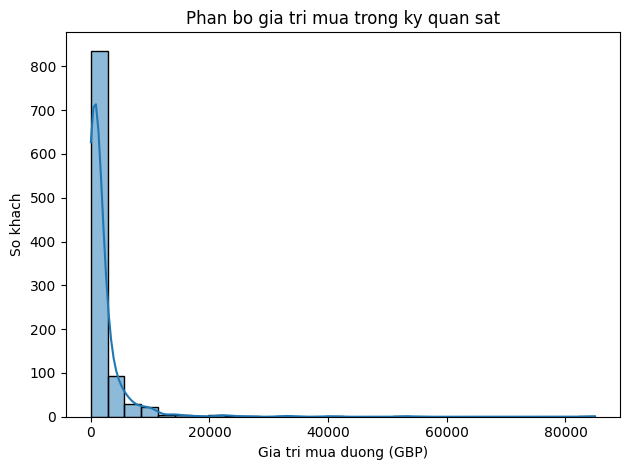

Median: 722.5050000000001 | Skewness: 9.594685789701465


In [21]:
sns.histplot(data=data, x='MonetaryGBP', bins=30, kde=True)
plt.title('Phan bo gia tri mua trong ky quan sat')
plt.xlabel('Gia tri mua duong (GBP)'); plt.ylabel('So khach')
plt.tight_layout(); plt.show(); plt.close()
print('Median:', data['MonetaryGBP'].median(), '| Skewness:', data['MonetaryGBP'].skew())


**Nhận xét:** Mean MonetaryGBP là 1,949.33, median 722.51 GBP; skewness 9.59. Phân phối lệch phải, một số khách giá trị lớn kéo mean lên. Stage 2 cần chuẩn hóa trước PCA/K-Means và kiểm tra sai số hồi quy ở nhóm giá trị lớn; chưa biến đổi dữ liệu hoặc hứa điểm số cao.

#### 2.2. IQR và boxplot — Ngoại lệ
Tính fence bằng Q1−1,5×IQR và Q3+1,5×IQR. Chỉ phát hiện; không tự xóa người mua nhiều.

Q1: 306.435 | Q3: 1829.7775000000001 | IQR: 1523.3425000000002 | Ngoai fence: 109


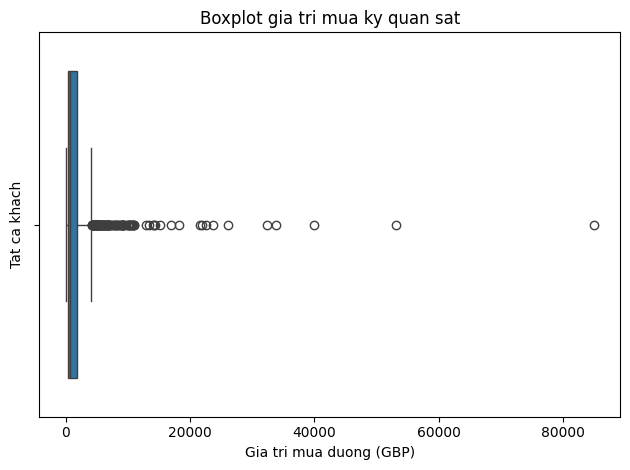

In [22]:
x = data['MonetaryGBP']
q1, q3 = x.quantile(0.25), x.quantile(0.75)
iqr = q3-q1
ngoai_le = (x < q1-1.5*iqr) | (x > q3+1.5*iqr)
print('Q1:', q1, '| Q3:', q3, '| IQR:', iqr, '| Ngoai fence:', ngoai_le.sum())
sns.boxplot(x=x)
plt.title('Boxplot gia tri mua ky quan sat')
plt.xlabel('Gia tri mua duong (GBP)'); plt.ylabel('Tat ca khach')
plt.tight_layout(); plt.show(); plt.close()


**Nhận xét:** Có 109/1000 khách (10.9%) ngoài fence IQR. Giữ họ vì mua lớn có thể hợp lệ, nhất là dữ liệu có người mua sỉ theo tài liệu UCI. Ngoại lệ ảnh hưởng khoảng cách và sai số nên cần xem khi so sánh mô hình; không xóa chỉ để biểu đồ đẹp.

#### 2.3. Bar chart — Nhãn phân loại
Kiểm tra số lượng và tỷ lệ có/không mua lại trước khi quyết định xử lý mất cân bằng.

,So_khach,Phan_tram
Mua_lai_90_ngay,,
0,557,55.7
1,443,44.3


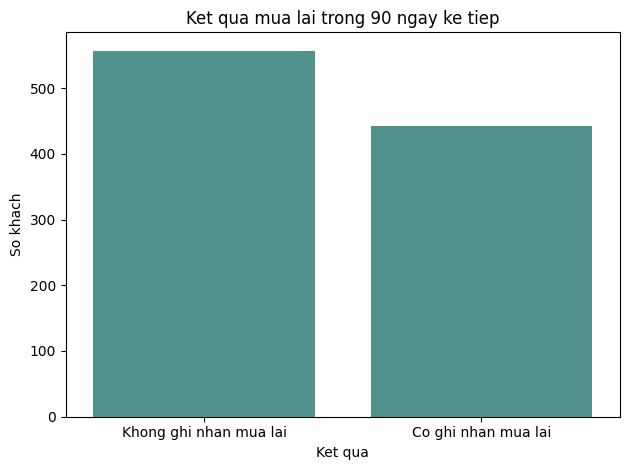

In [23]:
dem = data['Mua_lai_90_ngay'].value_counts().reindex([0, 1], fill_value=0)
display(pd.DataFrame({'So_khach': dem, 'Phan_tram': dem/len(data)*100}))
sns.barplot(x=['Khong ghi nhan mua lai', 'Co ghi nhan mua lai'], y=dem.values, color='#499b95')
plt.title('Ket qua mua lai trong 90 ngay ke tiep')
plt.xlabel('Ket qua'); plt.ylabel('So khach')
plt.tight_layout(); plt.show(); plt.close()


**Nhận xét — So what?** Có 443 khách mua lại (44,3%) và 557 khách không ghi nhận mua lại (55,7%) trong mẫu. Hai nhóm không chênh lệch quá lớn. Khi làm phân loại cần kiểm tra tỷ lệ hai nhóm và đánh giá thêm Precision, Recall, F1 ngoài Accuracy. Nhãn chỉ phản ánh kết quả trong 90 ngày.


### 3. Multivariate Analysis — Heatmap tương quan
Dùng Spearman để xem quan hệ khi dữ liệu có phân phối lệch. Đưa hai nhãn vào bảng tương quan để xem quan hệ với đặc trưng; không được dùng nhãn làm đầu vào mô hình.


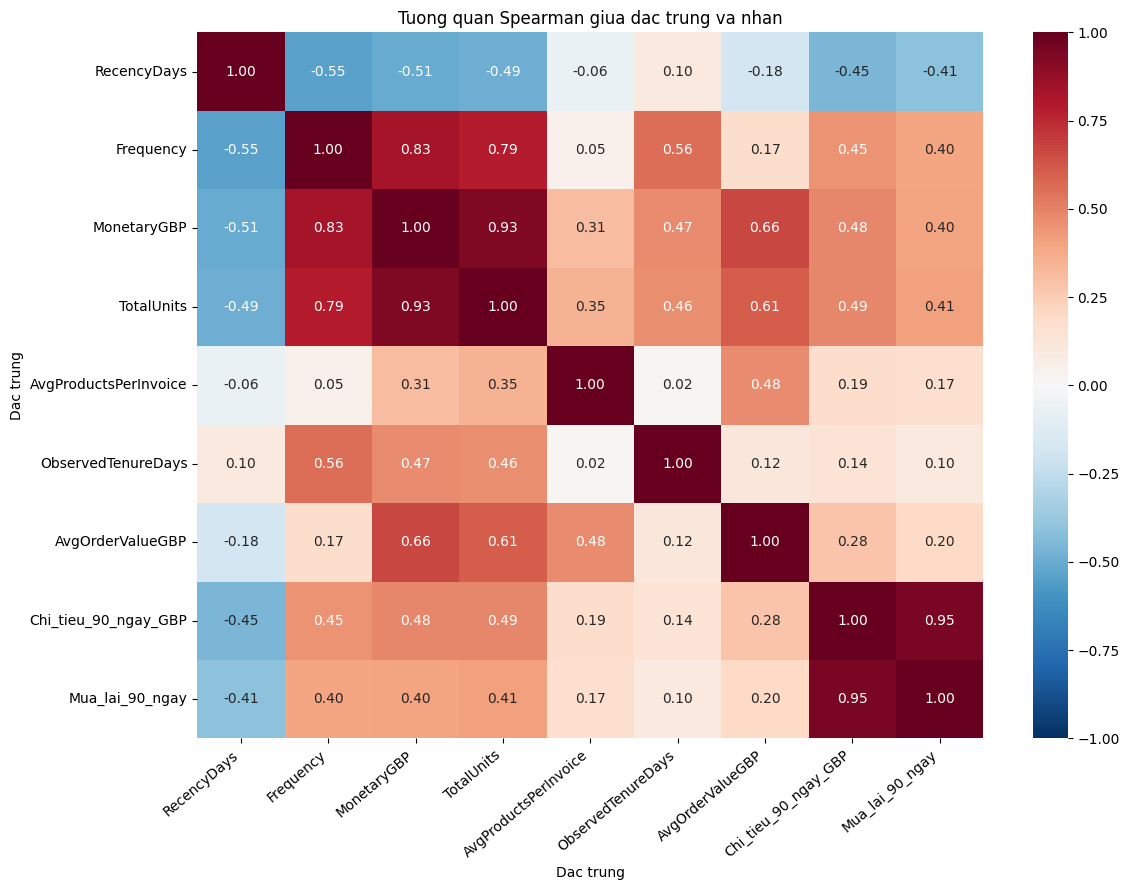

In [24]:
features = ['RecencyDays', 'Frequency', 'MonetaryGBP', 'TotalUnits',
            'AvgProductsPerInvoice', 'ObservedTenureDays', 'AvgOrderValueGBP']
cor = data[features + ['Chi_tieu_90_ngay_GBP', 'Mua_lai_90_ngay']].corr(method='spearman')
plt.figure(figsize=(12, 9))
sns.heatmap(cor, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1)
plt.title('Tuong quan Spearman giua dac trung va nhan')
plt.xlabel('Dac trung'); plt.ylabel('Dac trung')
plt.xticks(rotation=40, ha='right')
plt.tight_layout(); plt.show(); plt.close()


**Nhận xét:** Spearman Frequency–MonetaryGBP = 0.832, MonetaryGBP–TotalUnits = 0.932. Các biến chia sẻ thông tin; AvgOrderValueGBP còn được tính trực tiếp từ MonetaryGBP/Frequency. Đây là cơ sở thử PCA sau chuẩn hóa và so sánh K-Means có/không PCA, không chứng minh PCA chắc chắn cải thiện kết quả.

#### 3.1. Scatter — Đặc trưng và nhãn hồi quy
Vẽ MonetaryGBP kỳ trước so với giá trị mua dương kỳ sau. Các điểm ở y=0 là khách không có hóa đơn mua dương trong 90 ngày.

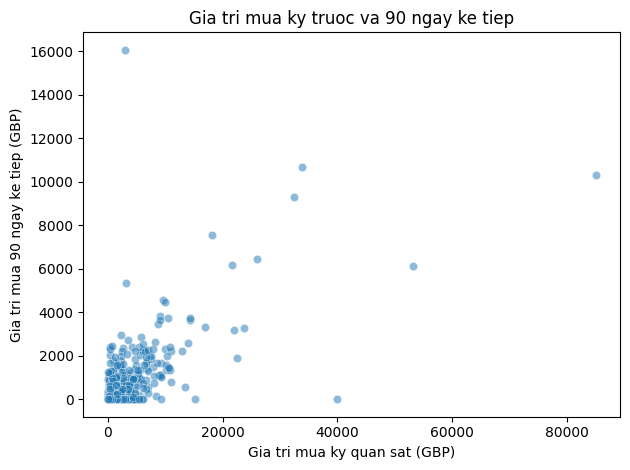

Pearson: 0.6610436900657811


In [25]:
sns.scatterplot(data=data, x='MonetaryGBP', y='Chi_tieu_90_ngay_GBP', alpha=0.5)
plt.title('Gia tri mua ky truoc va 90 ngay ke tiep')
plt.xlabel('Gia tri mua ky quan sat (GBP)'); plt.ylabel('Gia tri mua 90 ngay ke tiep (GBP)')
plt.tight_layout(); plt.show(); plt.close()
print('Pearson:', data['MonetaryGBP'].corr(data['Chi_tieu_90_ngay_GBP']))


**Nhận xét — So what?** Tương quan Pearson giữa MonetaryGBP kỳ trước và giá trị mua kỳ sau xấp xỉ 0,661. Có 557 khách có giá trị kỳ sau bằng 0 vì không ghi nhận mua dương trong 90 ngày. Chi tiêu trước đây có quan hệ với chi tiêu kỳ sau nhưng không dự đoán chính xác từng khách; khi làm hồi quy cần kiểm tra sai số, đặc biệt ở nhóm mua lớn.


#### 3.2. Groupby và grouped boxplot
So sánh Recency giữa nhóm mua lại/không mua lại. Recency nhỏ nghĩa là lần mua cuối gần mốc dự đoán hơn.

,count,mean,median,std
Mua_lai_90_ngay,,,,
0,557,233.276481,265.0,147.113653
1,443,114.356659,70.0,116.190276


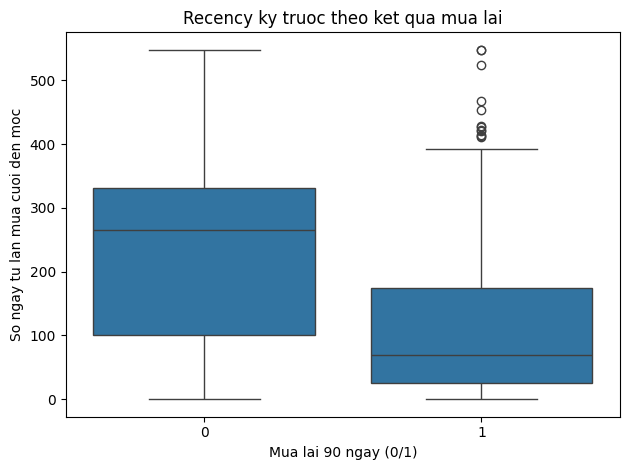

In [26]:
display(data.groupby('Mua_lai_90_ngay')['RecencyDays'].agg(['count', 'mean', 'median', 'std']))
sns.boxplot(data=data, x='Mua_lai_90_ngay', y='RecencyDays', order=[0, 1])
plt.title('Recency ky truoc theo ket qua mua lai')
plt.xlabel('Mua lai 90 ngay (0/1)'); plt.ylabel('So ngay tu lan mua cuoi den moc')
plt.tight_layout(); plt.show(); plt.close()


**Nhận xét:** Median Recency của nhóm không mua lại là 265.0 ngày, nhóm mua lại là 70.0 ngày. Trong mẫu, nhóm mua lại có lần mua cuối gần mốc hơn. Recency là feature biết trước kết quả, đáng thử cho phân loại; quan hệ quan sát không bảo đảm dự đoán chính xác từng khách hoặc chứng minh mua gần gây mua lại.

#### 3.3. Crosstab và stacked bar
So sánh tỷ lệ mua lại giữa khách ở UK và các quốc gia khác. Dùng nhóm địa lý từ Country thật để biểu đồ dễ đọc; không gán quốc gia cho khách không biết.

Mua_lai_90_ngay,0,1
RegionGroup,,
Other countries,51,47
United Kingdom,506,396


Mua_lai_90_ngay,0,1
RegionGroup,,
Other countries,52.040816,47.959184
United Kingdom,56.097561,43.902439


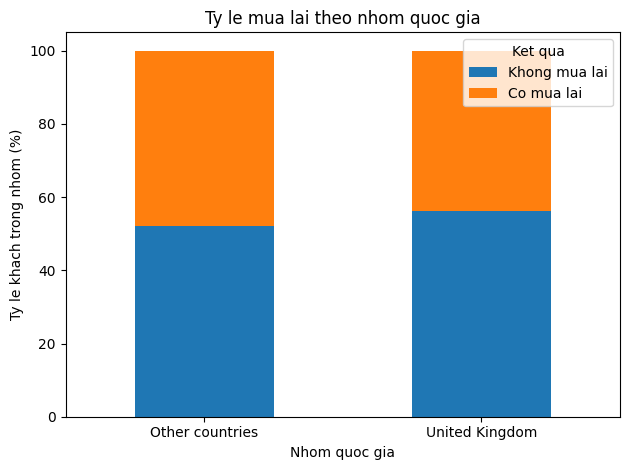

In [27]:
cheo = pd.crosstab(data['RegionGroup'], data['Mua_lai_90_ngay']).reindex(columns=[0, 1], fill_value=0)
display(cheo)
ty_le = cheo.div(cheo.sum(axis=1), axis=0)*100
display(ty_le)
ty_le.rename(columns={0: 'Khong mua lai', 1: 'Co mua lai'}).plot(kind='bar', stacked=True, rot=0)
plt.title('Ty le mua lai theo nhom quoc gia')
plt.xlabel('Nhom quoc gia'); plt.ylabel('Ty le khach trong nhom (%)'); plt.legend(title='Ket qua')
plt.tight_layout(); plt.show(); plt.close()


**Nhận xét:** Tỷ lệ mua lại theo nhóm: Other countries: 48.0%; United Kingdom: 43.9%. Cỡ mẫu các nhóm khác nhau nên dùng tỷ lệ cùng bảng số lượng. Không suy rộng thành quốc gia gây mua lại; tập khách thuộc một nhà bán lẻ và có thể có người mua sỉ. Bộ X cơ bản chỉ dùng các biến số để tránh phải mã hóa Country ở bản đầu.

### Kiểm tra và xuất dữ liệu sạch
Một dòng/khách, đủ nhãn, không thiếu. Lưu thêm bảng khách trong SQLite. Không xuất các file thống kê trung gian hoặc ảnh rời.

In [28]:
print('Số khách:', len(data))
print('Mỗi khách một dòng:', data['CustomerID'].is_unique)
print('Số ô thiếu:', data.isna().sum().sum())
print('Nhãn mua lại:', sorted(data['Mua_lai_90_ngay'].unique()))
print('Giá trị mua kỳ sau không âm:', (data['Chi_tieu_90_ngay_GBP'] >= 0).all())
print('Đặc trưng chỉ dùng trước mốc:', (truoc_moc['InvoiceDate'] < moc_du_doan).all())
print('Nhãn chỉ dùng từ mốc trở đi:', (sau_moc['InvoiceDate'] >= moc_du_doan).all())
data.to_csv('processed/data_khach_hang.csv', index=False, encoding='utf-8-sig')
with sqlite3.connect('csdl/retail.sqlite') as conn:
    data.to_sql('khach_hang', conn, if_exists='replace', index=False)
print('Đã xuất data_khach_hang.csv:', data.shape)

# Lưu cùng dữ liệu vào những vị trí chương trình hiện có đang đọc.
data.to_csv(ROOT / 'app' / 'data_khach_hang.csv', index=False, encoding='utf-8-sig')
data[['CustomerID'] + features + ['Chi_tieu_90_ngay_GBP']].to_csv(
    'processed/data_regression.csv', index=False, encoding='utf-8-sig')


Số khách: 1000
Mỗi khách một dòng: True
Số ô thiếu: 0
Nhãn mua lại: [np.int64(0), np.int64(1)]
Giá trị mua kỳ sau không âm: True
Đặc trưng chỉ dùng trước mốc: True
Nhãn chỉ dùng từ mốc trở đi: True
Đã xuất data_khach_hang.csv: (1000, 13)


## Kết quả Stage 1

- `data_goc/`: hai CSV gốc, không sửa dữ liệu nguồn.
- `du_lieu_mo_phong.csv`: kênh liên hệ giả định theo khách, sinh bằng NumPy.
- `csdl/`: dữ liệu được lưu và đọc lại từ SQLite và Qdrant local.
- `data_khach_hang.csv`: bảng sạch, một dòng mỗi khách.

| Cột | Ý nghĩa |
|---|---|
| CustomerID | Mã khách, không dùng làm đặc trưng số |
| RecencyDays | Số ngày từ lần mua cuối đến mốc 01/09/2011 |
| Frequency | Số hóa đơn trong kỳ quan sát |
| MonetaryGBP | Tổng giá trị mua dương trong kỳ quan sát |
| TotalUnits | Tổng số lượng mua trong kỳ quan sát |
| AvgProductsPerInvoice | Trung bình số mã hàng khác nhau mỗi hóa đơn |
| ObservedTenureDays | Số ngày từ lần mua đầu được quan sát đến mốc |
| AvgOrderValueGBP | Giá trị mua trung bình mỗi hóa đơn |
| Country / RegionGroup | Quốc gia ghi nhận cuối trước mốc / nhóm UK và các nước khác |
| Kenh_lien_he_mo_phong | Dữ liệu giả định, không dùng kết luận hành vi thật |
| Chi_tieu_90_ngay_GBP | Tổng giá trị mua dương trong 90 ngày tiếp theo, nhãn hồi quy |
| Mua_lai_90_ngay | 1 nếu có mua dương trong 90 ngày tiếp theo, ngược lại 0 |

Giá trị mua dương chưa trừ hoàn trả nên không gọi là doanh thu ròng. Không dùng hai nhãn tương lai, mã khách hoặc kênh mô phỏng làm đặc trưng. Các nhận xét EDA chỉ áp dụng cho mẫu khách đã chọn; không đại diện toàn bộ thị trường. Không tự xóa các dòng giống nhau vì dữ liệu không có mã dòng để xác minh chúng là lỗi ghi lặp.


# STAGE 2 — PCA

Các cell tiếp theo lấy từ `PCA.ipynb`.

In [29]:
from pathlib import Path

# Tìm thư mục dự án khi mở từ thư mục gốc hoặc notebooks.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'Data').is_dir() and (p / 'notebooks').is_dir())


In [30]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

In [31]:
df = pd.read_csv(ROOT / "Data/processed/data_khach_hang.csv")
df.head()

,CustomerID,Frequency,MonetaryGBP,TotalUnits,AvgProductsPerInvoice,Country,Kenh_lien_he_mo_phong,RecencyDays,ObservedTenureDays,AvgOrderValueGBP,Chi_tieu_90_ngay_GBP,Mua_lai_90_ngay,RegionGroup
0,12354,1,1079.40,530,58.000000,Spain,Email,132,132,1079.400000,0.00,0,Other countries
1,12358,3,1774.04,622,17.333333,Austria,Phone,50,450,591.346667,0.00,0,Other countries
2,12363,2,552.00,408,11.500000,Unspecified,SMS,9,142,276.000000,0.00,0,Other countries
3,12365,2,641.38,174,11.000000,Cyprus,SMS,191,191,320.690000,0.00,0,Other countries
4,12370,5,3018.07,2053,29.600000,Cyprus,SMS,174,524,603.614000,739.28,1,Other countries


In [32]:

print(df["Frequency"].skew().round(2))
print(df["MonetaryGBP"].skew().round(2))
print(df["TotalUnits"].skew().round(2))
print(df["AvgProductsPerInvoice"].skew().round(2))
print(df["RecencyDays"].skew().round(2))
print(df["ObservedTenureDays"].skew().round(2))
print(df["AvgOrderValueGBP"].skew().round(2))

5.3
9.59
14.3
3.29
0.57
-0.71
16.67


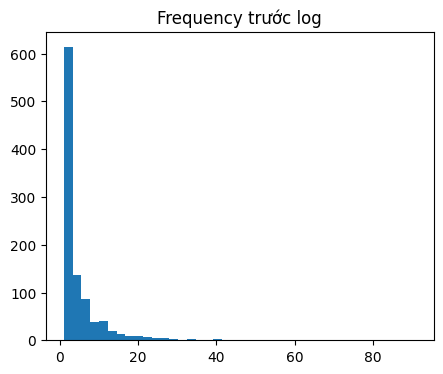

In [33]:
plt.figure(figsize=(5,4))
plt.hist(df["Frequency"], bins=40)
plt.title("Frequency trước log")
plt.show()

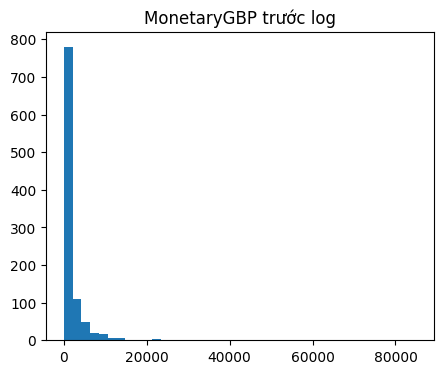

In [34]:
plt.figure(figsize=(5,4))
plt.hist(df["MonetaryGBP"], bins=40)
plt.title("MonetaryGBP trước log")
plt.show()

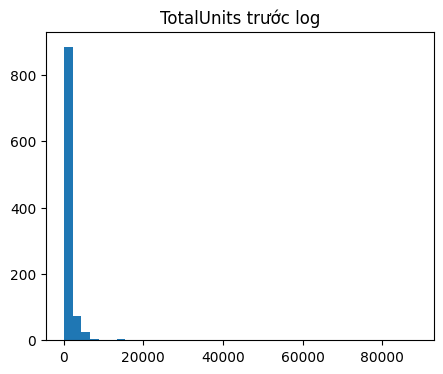

In [35]:
plt.figure(figsize=(5,4))
plt.hist(df["TotalUnits"], bins=40)
plt.title("TotalUnits trước log")
plt.show()

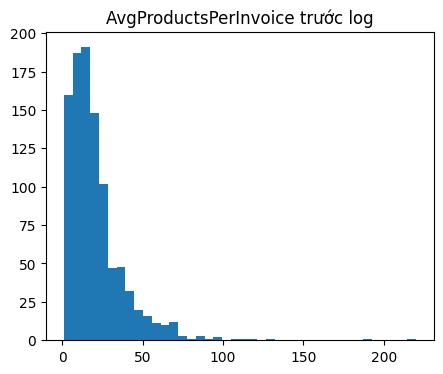

In [36]:
plt.figure(figsize=(5,4))
plt.hist(df["AvgProductsPerInvoice"], bins=40)
plt.title("AvgProductsPerInvoice trước log")
plt.show()

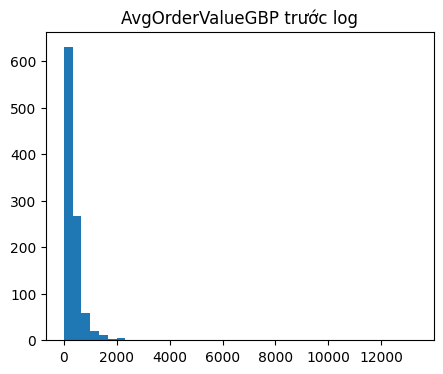

In [37]:
plt.figure(figsize=(5,4))
plt.hist(df["AvgOrderValueGBP"], bins=40)
plt.title("AvgOrderValueGBP trước log")
plt.show()

In [38]:
df2 =  df.drop(columns=['CustomerID', 'Chi_tieu_90_ngay_GBP','Mua_lai_90_ngay','Country','RegionGroup','Kenh_lien_he_mo_phong'])
df2.head()

,Frequency,MonetaryGBP,TotalUnits,AvgProductsPerInvoice,RecencyDays,ObservedTenureDays,AvgOrderValueGBP
0,1,1079.40,530,58.000000,132,132,1079.400000
1,3,1774.04,622,17.333333,50,450,591.346667
2,2,552.00,408,11.500000,9,142,276.000000
3,2,641.38,174,11.000000,191,191,320.690000
4,5,3018.07,2053,29.600000,174,524,603.614000


In [39]:
log_cols = ["Frequency", "MonetaryGBP", "TotalUnits", "AvgProductsPerInvoice", "AvgOrderValueGBP"]
df2_log = df2.copy()
df2_log[log_cols] = np.log1p(df2_log[log_cols])

In [40]:
print(df2_log["Frequency"].skew().round(2))
print(df2_log["MonetaryGBP"].skew().round(2))
print(df2_log["TotalUnits"].skew().round(2))
print(df2_log["AvgProductsPerInvoice"].skew().round(2))
print(df2_log["RecencyDays"].skew().round(2))
print(df2_log["ObservedTenureDays"].skew().round(2))
print(df2_log["AvgOrderValueGBP"].skew().round(2))

1.01
0.17
-0.21
-0.38
0.57
-0.71
-0.11


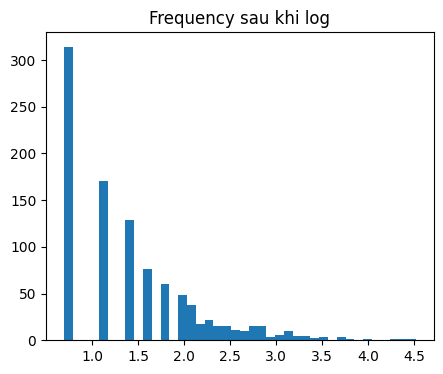

In [41]:
plt.figure(figsize=(5,4))
plt.hist(df2_log["Frequency"], bins=40)
plt.title("Frequency sau khi log")
plt.show()

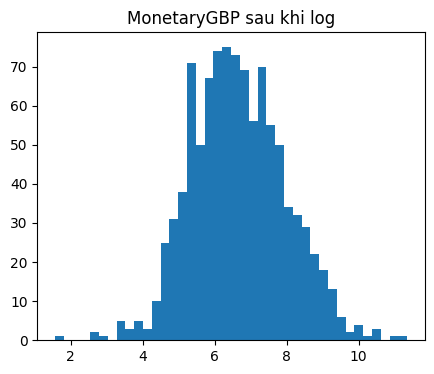

In [42]:
plt.figure(figsize=(5,4))
plt.hist(df2_log["MonetaryGBP"], bins=40)
plt.title("MonetaryGBP sau khi log")
plt.show()

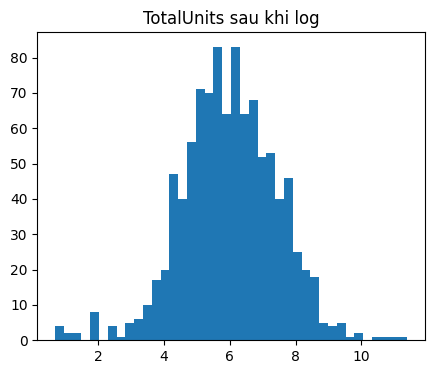

In [43]:
plt.figure(figsize=(5,4))
plt.hist(df2_log["TotalUnits"], bins=40)
plt.title("TotalUnits sau khi log")
plt.show()

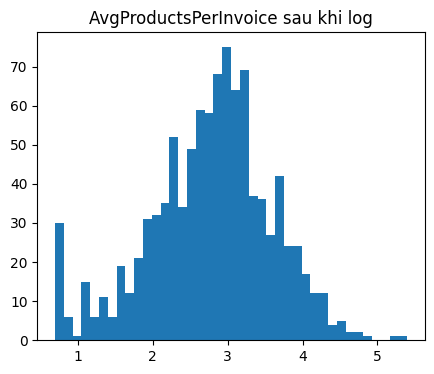

In [44]:
plt.figure(figsize=(5,4))
plt.hist(df2_log["AvgProductsPerInvoice"], bins=40)
plt.title("AvgProductsPerInvoice sau khi log")
plt.show()

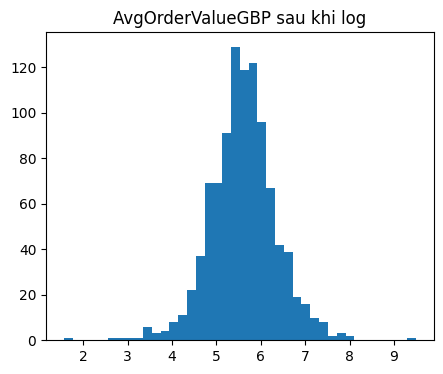

In [45]:
plt.figure(figsize=(5,4))
plt.hist(df2_log["AvgOrderValueGBP"], bins=40)
plt.title("AvgOrderValueGBP sau khi log")
plt.show()

In [46]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df2_log)

pca_full = PCA(random_state=42).fit(X_scaled)
evr = pca_full.explained_variance_ratio_     # phương sai từng thành phần
cum = np.cumsum(evr)                         # phương sai tích lũy
print(evr.round(3))
print(cum.round(3))

[0.521 0.191 0.168 0.079 0.025 0.016 0.   ]
[0.521 0.712 0.88  0.958 0.983 1.    1.   ]


In [47]:
TARGET = 0.85
n = int(np.argmax(cum >= TARGET) + 1)
print(f"==> Chọn {n} thành phần, giữ {cum[n-1]:.1%} phương sai")

# So sánh: chỉ chuẩn hóa vs. log1p + chuẩn hóa (số thành phần cho 85% / 90% / 95%)
def so_thanh_phan(data):
    Z = StandardScaler().fit_transform(data)
    c = np.cumsum(PCA(random_state=42).fit(Z).explained_variance_ratio_)
    return [int(np.argmax(c >= t) + 1) for t in (0.85, 0.90, 0.95)]

print("Chỉ StandardScaler    :", so_thanh_phan(df2))
print("log1p + StandardScaler:", so_thanh_phan(df2_log))

==> Chọn 3 thành phần, giữ 88.0% phương sai
Chỉ StandardScaler    : [4, 5, 6]
log1p + StandardScaler: [3, 4, 4]


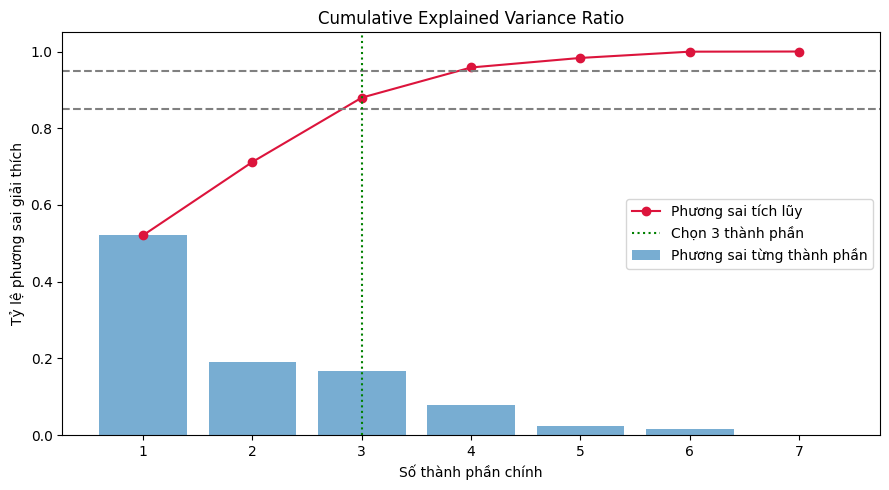

In [48]:
x = np.arange(1, len(evr) + 1)
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x, evr, alpha=0.6, label="Phương sai từng thành phần")
ax.plot(x, cum, marker="o", color="crimson", label="Phương sai tích lũy")
ax.axhline(0.85, ls="--", color="gray")
ax.axhline(0.95, ls="--", color="gray")
ax.axvline(n, ls=":", color="green", label=f"Chọn {n} thành phần")
ax.set_xlabel("Số thành phần chính")
ax.set_ylabel("Tỷ lệ phương sai giải thích")
ax.set_title("Cumulative Explained Variance Ratio")
ax.legend(loc="center right")
plt.tight_layout()
plt.savefig("pca_variance.png", dpi=150)
plt.show()

In [49]:
pca = PCA(n_components=n, random_state=42)
X_pca = pca.fit_transform(X_scaled)

pc_cols = [f"PC{i+1}" for i in range(n)]
df_pca = pd.DataFrame(X_pca, columns=pc_cols)
df_pca.insert(0, "CustomerID", df["CustomerID"].values)   # lấy từ df gốc

print("Phương sai giữ lại:", pca.explained_variance_ratio_.sum().round(3))
df_pca.head()
df_pca.to_csv(ROOT / "Data/processed/pca_features.csv", index=False, encoding="utf-8-sig")


Phương sai giữ lại: 0.88


In [50]:
print(len(df) == len(df2_log))
print((df.index == df2_log.index).all())

True
True


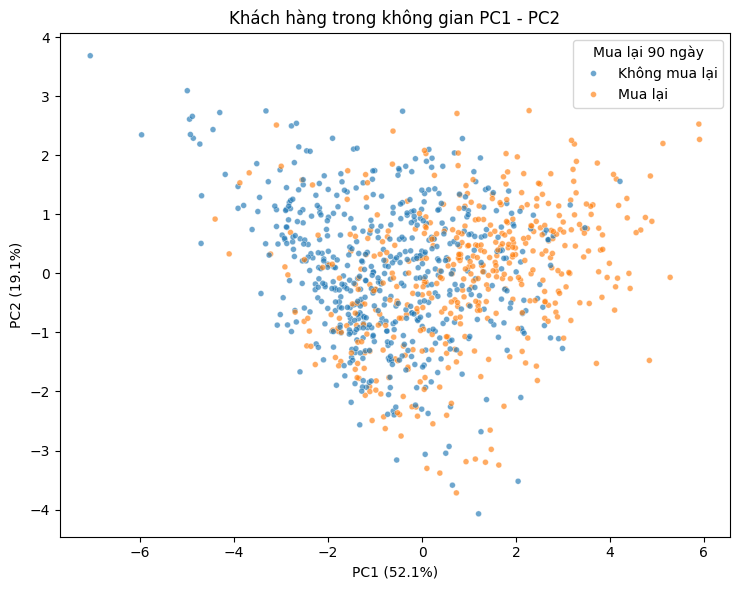

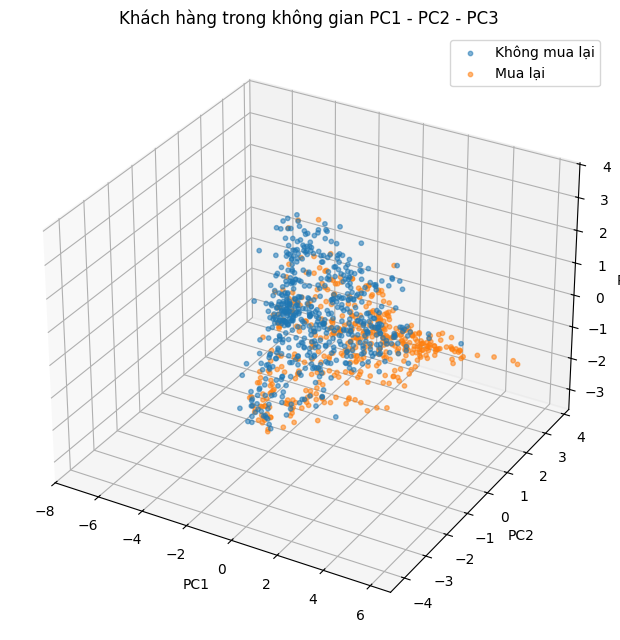

In [51]:
nhan = df["Mua_lai_90_ngay"].map({0: "Không mua lại", 1: "Mua lại"})

# --- 2D ---
plt.figure(figsize=(7.5, 6))
sns.scatterplot(x=df_pca["PC1"], y=df_pca["PC2"], hue=nhan, s=18, alpha=0.65)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.title("Khách hàng trong không gian PC1 - PC2")
plt.legend(title="Mua lại 90 ngày")
plt.tight_layout()
plt.savefig("pca_scatter_2d.png", dpi=150)
plt.show()

# --- 3D (cần ít nhất 3 thành phần) ---
if n >= 3:
    fig = plt.figure(figsize=(8, 6.5))
    ax3 = fig.add_subplot(111, projection="3d")
    for gia_tri, mau in [("Không mua lại", "tab:blue"), ("Mua lại", "tab:orange")]:
        m = (nhan == gia_tri).values
        ax3.scatter(df_pca.loc[m, "PC1"], df_pca.loc[m, "PC2"], df_pca.loc[m, "PC3"],
                    s=10, alpha=0.55, color=mau, label=gia_tri)
    ax3.set_xlabel("PC1"); ax3.set_ylabel("PC2"); ax3.set_zlabel("PC3")
    ax3.set_title("Khách hàng trong không gian PC1 - PC2 - PC3")
    ax3.legend()
    plt.tight_layout()
    plt.savefig("pca_scatter_3d.png", dpi=150)
    plt.show()

                        PC1   PC2   PC3
Frequency              0.43  0.39 -0.20
MonetaryGBP            0.51  0.03 -0.00
TotalUnits             0.50 -0.00  0.03
AvgProductsPerInvoice  0.22 -0.55  0.34
RecencyDays           -0.29  0.13  0.72
ObservedTenureDays     0.23  0.57  0.51
AvgOrderValueGBP       0.35 -0.45  0.26


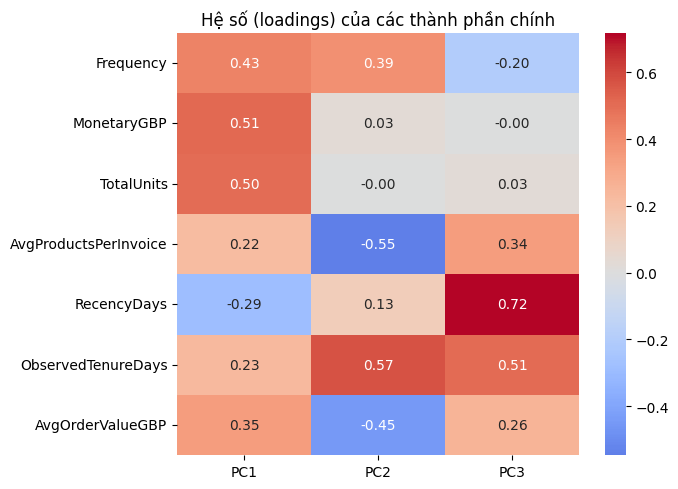

In [52]:
loadings = pd.DataFrame(pca.components_.T, index=df2.columns, columns=pc_cols)
print(loadings.round(2))

plt.figure(figsize=(7, 5))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Hệ số (loadings) của các thành phần chính")
plt.tight_layout()
plt.savefig("pca_loadings.png", dpi=150)
plt.show()

### Bổ sung kết nối PCA → UI
Lưu đúng scaler và PCA vừa học; UI dùng lại thay vì tự fit một bản PCA khác.

In [53]:
import joblib
joblib.dump({'scaler': scaler, 'pca': pca, 'features': df2.columns.tolist(), 'log_columns': log_cols}, ROOT / 'models' / 'PCA.joblib')
pca_summary = {'n_components': n, 'variance': float(cum[n-1])}

# STAGE 2 — KMeans

Các cell tiếp theo lấy từ `KMeans.ipynb`.

# K-Means phân khúc khách hàng

    Phần Task 2 được tách riêng từ Stage2 đã ghép PCA của nhóm. Chạy lần lượt các ô từ đầu, không cần chạy notebook Stage2.

    Đầu vào PCA là `pca_features.csv` lấy từ kết quả `duanpython`. K-Means chỉ sử dụng PC1, PC2, PC3; CustomerID dùng để ghép đúng khách hàng. Dữ liệu lịch sử được dùng để so sánh với cách không giảm chiều và để mô tả cụm.

## 1 Đọc dữ liệu và ghép PC theo CustomerID

In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
from pathlib import Path

# Tìm thư mục dự án khi mở từ thư mục gốc hoặc notebooks.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'Data').is_dir() and (p / 'notebooks').is_dir())
BASE_DIR = ROOT / "Data/processed"
RESULT_DIR = ROOT / "app"
RESULT_DIR.mkdir(exist_ok=True)
FEATURES = [
    "RecencyDays", "Frequency", "MonetaryGBP", "TotalUnits",
    "AvgProductsPerInvoice", "ObservedTenureDays", "AvgOrderValueGBP"
]
PCA_FEATURES = [
    "Frequency", "MonetaryGBP", "TotalUnits", "AvgProductsPerInvoice",
    "RecencyDays", "ObservedTenureDays", "AvgOrderValueGBP"
]
LOG_COLUMNS = [
    "Frequency", "MonetaryGBP", "TotalUnits",
    "AvgProductsPerInvoice", "AvgOrderValueGBP"
]
# Biến tương lai chỉ dùng mô tả sau khi có cụm; không tham gia fit K-Means.
REG_TARGET = "Chi_tieu_90_ngay_GBP"
PC_COLUMNS = [col for col in pd.read_csv(BASE_DIR / "pca_features.csv", nrows=0).columns if col.startswith("PC")]

data = pd.read_csv(BASE_DIR / "data_khach_hang.csv")
pca_data = pd.read_csv(BASE_DIR / "pca_features.csv")
assert data["CustomerID"].is_unique and pca_data["CustomerID"].is_unique
assert set(data["CustomerID"]) == set(pca_data["CustomerID"]), "Hai tệp phải có cùng khách hàng."
# loc sắp xếp lại PC theo đúng thứ tự khách hàng của CSV gốc.
pca_aligned = pca_data.set_index("CustomerID").loc[data["CustomerID"], PC_COLUMNS]
X_pca = pca_aligned.to_numpy()
assert np.isfinite(X_pca).all(), "Dữ liệu PC thiếu hoặc không hợp lệ."
assert np.isfinite(data[FEATURES].to_numpy(dtype=float)).all()
assert (data[FEATURES] >= 0).all().all()
print("Số khách hàng:", len(data))
print("Kích thước dữ liệu PCA:", X_pca.shape)
display(data.head())
display(pca_aligned.head())

Số khách hàng: 1000
Kích thước dữ liệu PCA: (1000, 3)


,CustomerID,Frequency,MonetaryGBP,TotalUnits,AvgProductsPerInvoice,Country,Kenh_lien_he_mo_phong,RecencyDays,ObservedTenureDays,AvgOrderValueGBP,Chi_tieu_90_ngay_GBP,Mua_lai_90_ngay,RegionGroup
0,12354,1,1079.40,530,58.000000,Spain,Email,132,132,1079.400000,0.00,0,Other countries
1,12358,3,1774.04,622,17.333333,Austria,Phone,50,450,591.346667,0.00,0,Other countries
2,12363,2,552.00,408,11.500000,Unspecified,SMS,9,142,276.000000,0.00,0,Other countries
3,12365,2,641.38,174,11.000000,Cyprus,SMS,191,191,320.690000,0.00,0,Other countries
4,12370,5,3018.07,2053,29.600000,Cyprus,SMS,174,524,603.614000,739.28,1,Other countries


,PC1,PC2,PC3
CustomerID,,,
12354,0.505565,-3.045908,0.194336
12358,1.222284,-0.376677,-0.016404
12363,-0.397573,-1.053059,-1.614249
12365,-0.850635,-0.763688,-0.536342
12370,2.096434,-0.112264,0.972179


## 2 Chuẩn bị đầu vào so sánh trước khi giảm chiều

    Lấy đúng 7 cột và biến đổi log1p cho đúng 5 cột như phần PCA của nhóm, sau đó StandardScaler. Các PC đã có sẵn nên không fit lại PCA trong phần K-Means này.

In [55]:
X_log = data[PCA_FEATURES].copy()
X_log[LOG_COLUMNS] = np.log1p(X_log[LOG_COLUMNS])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)
print("Dữ liệu trước khi giảm chiều:", X_scaled.shape)
print("Dữ liệu sau PCA:", X_pca.shape)

Dữ liệu trước khi giảm chiều: (1000, 7)
Dữ liệu sau PCA: (1000, 3)


## 3 Thử K từ 2 đến 10 bằng WCSS và Silhouette

In [56]:
K_RANGE = range(2, 11)
ket_qua_cum_goc = []
ket_qua_cum_pca = []

for k in K_RANGE:
    # K-Means trên 7 đặc trưng đã log1p và chuẩn hóa
    model_goc = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    nhan_goc = model_goc.fit_predict(X_scaled)
    ket_qua_cum_goc.append({
        "K": k,
        "WCSS": model_goc.inertia_,
        "Silhouette": silhouette_score(X_scaled, nhan_goc)
    })

    # K-Means trên dữ liệu PCA
    model_pca = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    nhan_pca = model_pca.fit_predict(X_pca)
    ket_qua_cum_pca.append({
        "K": k,
        "WCSS": model_pca.inertia_,
        "Silhouette": silhouette_score(X_pca, nhan_pca)
    })

scores_goc = pd.DataFrame(ket_qua_cum_goc)
scores_pca = pd.DataFrame(ket_qua_cum_pca)

print("=== K-Means trên 7 đặc trưng log + scale ===")
display(scores_goc.round(4))
print("=== K-Means trên dữ liệu PCA ===")
display(scores_pca.round(4))

=== K-Means trên 7 đặc trưng log + scale ===


,K,WCSS,Silhouette
0,2,4604.0998,0.2966
1,3,3819.7473,0.2344
2,4,3288.3051,0.2473
3,5,2898.5162,0.2224
4,6,2644.0500,0.2206
5,7,2467.7410,0.2157
6,8,2314.3022,0.2027
7,9,2206.7358,0.1912
8,10,2093.5091,0.2000


=== K-Means trên dữ liệu PCA ===


,K,WCSS,Silhouette
0,2,3764.5841,0.3375
1,3,2983.6033,0.2793
2,4,2453.6059,0.2959
3,5,2076.4923,0.2761
4,6,1829.0790,0.2785
5,7,1657.4071,0.2772
6,8,1513.4063,0.2628
7,9,1399.3750,0.2569
8,10,1301.2586,0.2518


## 4 Vẽ Elbow và Silhouette

    Đường Elbow cho thấy WCSS giảm khi tăng K. Silhouette đo mức độ gần nhau trong cụm và tách biệt giữa các cụm. Cần xem cùng hồ sơ cụm; WCSS giữa hai không gian không so sánh trực tiếp.

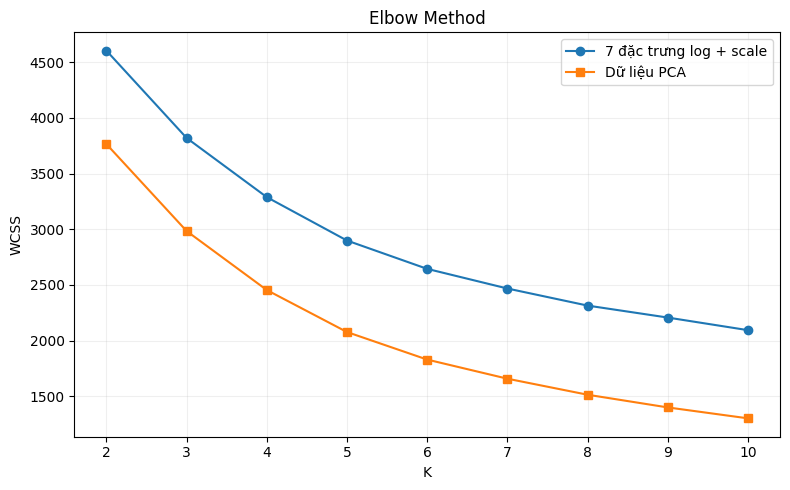

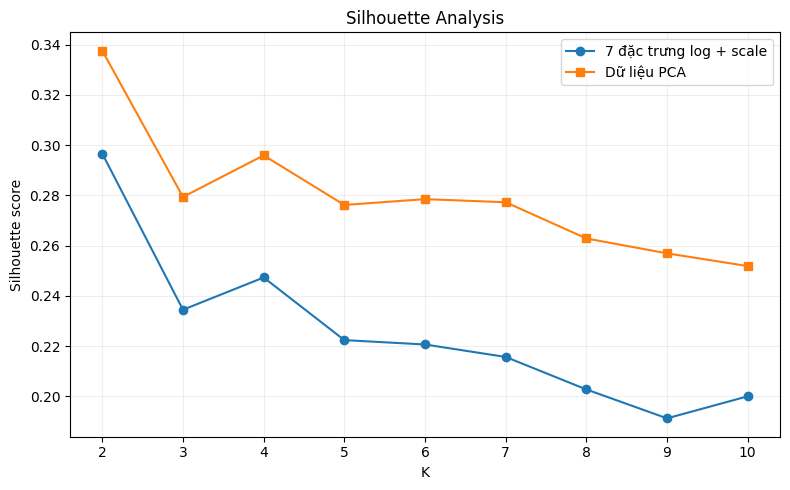

In [57]:
# Elbow: WCSS theo K
plt.figure(figsize=(8, 5))
plt.plot(scores_goc["K"], scores_goc["WCSS"], marker="o", label="7 đặc trưng log + scale")
plt.plot(scores_pca["K"], scores_pca["WCSS"], marker="s", label="Dữ liệu PCA")
plt.xlabel("K")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(RESULT_DIR / "kmeans_elbow.png", dpi=150)
plt.show()

# Silhouette so sánh 7 đặc trưng log + scale và PCA
plt.figure(figsize=(8, 5))
plt.plot(scores_goc["K"], scores_goc["Silhouette"], marker="o", label="7 đặc trưng log + scale")
plt.plot(scores_pca["K"], scores_pca["Silhouette"], marker="s", label="Dữ liệu PCA")
plt.xlabel("K")
plt.ylabel("Silhouette score")
plt.title("Silhouette Analysis")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(RESULT_DIR / "kmeans_silhouette.png", dpi=150)
plt.show()

## 5 Chọn K và huấn luyện mô hình cuối

In [58]:
# Chọn K có Silhouette cao nhất ở từng cách biểu diễn dữ liệu
best_k_goc = int(scores_goc.loc[scores_goc["Silhouette"].idxmax(), "K"])
best_k_pca = int(scores_pca.loc[scores_pca["Silhouette"].idxmax(), "K"])

print("K tốt nhất - 7 đặc trưng log + scale:", best_k_goc)
print("K tốt nhất - dữ liệu PCA:", best_k_pca)

# Dùng K của PCA để tạo cột Cluster_Label cho dữ liệu chính
K = best_k_pca
kmeans_goc = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=20)
labels_goc = kmeans_goc.fit_predict(X_scaled)
kmeans_pca = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=20)
labels_pca = kmeans_pca.fit_predict(X_pca)

comparison_cluster = pd.DataFrame({
    "Model": ["K-Means LogScaled", "K-Means PCA"],
    "K": [K, K],
    "WCSS": [kmeans_goc.inertia_, kmeans_pca.inertia_],
    "Silhouette": [
        silhouette_score(X_scaled, labels_goc),
        silhouette_score(X_pca, labels_pca)
    ]
})
display(comparison_cluster.round(4))
print("Lưu ý: không so sánh trực tiếp WCSS giữa hai không gian có số chiều khác nhau; Silhouette cũng phụ thuộc không gian, cần xem thêm kích thước và hồ sơ cụm.")

K tốt nhất - 7 đặc trưng log + scale: 2
K tốt nhất - dữ liệu PCA: 2


,Model,K,WCSS,Silhouette
0,K-Means LogScaled,2,4604.0998,0.2966
1,K-Means PCA,2,3764.5841,0.3375


Lưu ý: không so sánh trực tiếp WCSS giữa hai không gian có số chiều khác nhau; Silhouette cũng phụ thuộc không gian, cần xem thêm kích thước và hồ sơ cụm.


## 6 Gắn nhãn và mô tả cụm bằng đơn vị gốc

    K-Means sử dụng cả 3 PC; biểu đồ PC1–PC2 chỉ minh họa phép chiếu 2D. Chi tiêu thực tế 90 ngày chỉ được tổng hợp sau phân cụm. Cluster 0 và Cluster 1 là mã cụm, không phải nhãn mua lại.

,So_khach,RecencyDays,Frequency,MonetaryGBP,TotalUnits,AvgProductsPerInvoice,ObservedTenureDays,AvgOrderValueGBP,Chi_tieu_90_ngay_GBP
Cluster_Label,,,,,,,,,
0,568,240.86,1.80,411.60,221.70,17.52,310.36,253.63,144.19
1,432,101.35,8.93,3971.15,2477.41,25.02,445.66,513.04,787.88


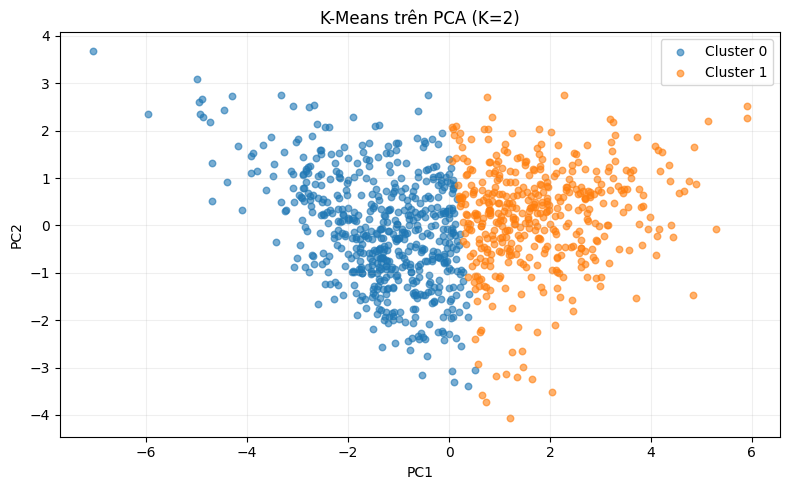

In [59]:
# Gắn nhãn cụm vào dữ liệu và xem đặc điểm trung bình từng cụm
data_stage2 = data.copy()
data_stage2["Cluster_Label"] = labels_pca

profile_cluster = data_stage2.groupby("Cluster_Label")[FEATURES + [REG_TARGET]].mean().round(2)
profile_cluster.insert(0, "So_khach", data_stage2.groupby("Cluster_Label").size())
display(profile_cluster)

plt.figure(figsize=(8, 5))
for cluster_id in sorted(data_stage2["Cluster_Label"].unique()):
    mask = data_stage2["Cluster_Label"] == cluster_id
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], s=22, alpha=0.6, label=f"Cluster {cluster_id}")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(f"K-Means trên PCA (K={K})")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(RESULT_DIR / "kmeans_clusters.png", dpi=150)
plt.show()

## 7 Lưu kết quả riêng

    Kết quả của bộ dữ liệu này: K = 2; Silhouette trên PCA khoảng 0,3375. Cluster 0 có 568 khách, Cluster 1 có 432 khách. Xem báo cáo Word để sử dụng phần diễn giải.

In [60]:
data_stage2.to_csv(RESULT_DIR / "data_khach_hang_kmeans.csv", index=False, encoding="utf-8-sig")
scores_goc.to_csv(RESULT_DIR / "scores_logscaled.csv", index=False)
scores_pca.to_csv(RESULT_DIR / "scores_pca.csv", index=False)
comparison_cluster.to_csv(RESULT_DIR / "comparison.csv", index=False)
profile_cluster.to_csv(RESULT_DIR / "cluster_profile.csv", encoding="utf-8-sig")
joblib.dump(kmeans_pca, RESULT_DIR / "kmeans_pca.pkl")
print("Đã lưu code chạy riêng, biểu đồ, bảng kết quả và nhãn cụm tại:", RESULT_DIR)

Đã lưu code chạy riêng, biểu đồ, bảng kết quả và nhãn cụm tại: c:\Users\tai33\Desktop\Project_Team_9-main (1)\Project_Team_9-main\app


In [61]:
cluster_summary = comparison_cluster.copy()
cluster_counts = data_stage2["Cluster_Label"].value_counts().sort_index()

# STAGE 2 — Regression

Các cell tiếp theo lấy từ `Regression.ipynb`.

# Regression dự đoán chi tiêu khách hàng trong 90 ngày

Phần **Task 3 – Regression** được tách từ `Stage2_Final.ipynb` để chạy và làm báo cáo riêng.

**Mục tiêu:** dự đoán `Chi_tieu_90_ngay_GBP` từ 7 đặc trưng lịch sử. So sánh
`LinearRegression` và `DecisionTreeRegressor`, sử dụng 80% dữ liệu huấn luyện và 20% kiểm tra.

Chạy các ô từ trên xuống. Mở notebook trong thư mục đã giải nén có `data_regression.csv`.

## 1 Khai báo thư viện và các cột sử dụng

`CustomerID` chỉ dùng để đối chiếu khách hàng. Biến mục tiêu và các thông tin tương lai
không được đưa vào tập đặc trưng đầu vào.

In [62]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

RANDOM_STATE = 42
TEST_SIZE = 0.20
FEATURES = [
    "RecencyDays", "Frequency", "MonetaryGBP", "TotalUnits",
    "AvgProductsPerInvoice", "ObservedTenureDays", "AvgOrderValueGBP"
]
REG_TARGET = "Chi_tieu_90_ngay_GBP"

# File .py lấy đường dẫn theo vị trí của nó; notebook dùng thư mục đang mở.
from pathlib import Path

# Tìm thư mục dự án khi mở từ thư mục gốc hoặc notebooks.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'Data').is_dir() and (p / 'notebooks').is_dir())
PROJECT_DIR = ROOT / "notebooks"
DATA_PATH = ROOT / "Data/processed/data_regression.csv"
OUTPUT_DIR = PROJECT_DIR / "ket_qua"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 2 Đọc và kiểm tra dữ liệu

Tệp dữ liệu gồm 1.000 khách hàng, giữ nguyên giá trị và thứ tự từ dữ liệu Stage2.
Chỉ cần các cột dùng cho Regression; mỗi dòng là một khách hàng.

In [63]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Không tìm thấy data_regression.csv. Hãy mở notebook trong thư mục Regression_Rieng."
    )

data = pd.read_csv(DATA_PATH)
required_columns = FEATURES + [REG_TARGET]
missing_columns = [col for col in required_columns if col not in data.columns]
if missing_columns:
    raise ValueError(f"Thiếu cột dữ liệu: {missing_columns}")

# Giữ cách xử lý của Stage2: loại dòng thiếu ở các cột cần sử dụng.
rows_before = len(data)
data = data.dropna(subset=required_columns).reset_index(drop=True)
print("Số khách hàng:", len(data))
print("Số dòng thiếu đã loại:", rows_before - len(data))
print("Số đặc trưng đầu vào:", len(FEATURES))
print(data.head().to_string(index=False))

Số khách hàng: 1000
Số dòng thiếu đã loại: 0
Số đặc trưng đầu vào: 7
 CustomerID  RecencyDays  Frequency  MonetaryGBP  TotalUnits  AvgProductsPerInvoice  ObservedTenureDays  AvgOrderValueGBP  Chi_tieu_90_ngay_GBP
      12354          132          1      1079.40         530              58.000000                 132       1079.400000                  0.00
      12358           50          3      1774.04         622              17.333333                 450        591.346667                  0.00
      12363            9          2       552.00         408              11.500000                 142        276.000000                  0.00
      12365          191          2       641.38         174              11.000000                 191        320.690000                  0.00
      12370          174          5      3018.07        2053              29.600000                 524        603.614000                739.28


## 3 Chia tập huấn luyện và tập kiểm tra

Tập huấn luyện chiếm 80%, tập kiểm tra chiếm 20%. Cả hai mô hình dùng cùng một lần
chia với `random_state=42` để có thể đối chiếu kết quả.

In [64]:
X_reg = data[FEATURES].copy()
y_reg = data[REG_TARGET].copy()

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

print("Số khách hàng huấn luyện:", len(X_train_r))
print("Số khách hàng kiểm tra:", len(X_test_r))

Số khách hàng huấn luyện: 800
Số khách hàng kiểm tra: 200


## 4 Huấn luyện Linear Regression

Chuẩn hóa các đặc trưng bằng `StandardScaler`. Scaler chỉ học trung bình và độ lệch
chuẩn từ tập huấn luyện; tập kiểm tra dùng lại scaler này để tránh rò rỉ dữ liệu.

In [65]:
scaler_reg = StandardScaler()
X_train_r_scaled = scaler_reg.fit_transform(X_train_r)
X_test_r_scaled = scaler_reg.transform(X_test_r)

linear_model = LinearRegression()
linear_model.fit(X_train_r_scaled, y_train_r)
pred_linear = linear_model.predict(X_test_r_scaled)

print("Đã huấn luyện LinearRegression và dự đoán tập kiểm tra.")

Đã huấn luyện LinearRegression và dự đoán tập kiểm tra.


## 5 Huấn luyện Decision Tree Regressor

Cây quyết định dùng các đặc trưng gốc, với `max_depth=5` và `random_state=42`,
giữ nguyên thông số trong Stage2.

In [66]:
tree_reg_model = DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE)
tree_reg_model.fit(X_train_r, y_train_r)
pred_tree = tree_reg_model.predict(X_test_r)

print("Đã huấn luyện DecisionTreeRegressor và dự đoán tập kiểm tra.")

Đã huấn luyện DecisionTreeRegressor và dự đoán tập kiểm tra.


## 6 Đánh giá và so sánh hai mô hình

- **MSE:** trung bình bình phương sai số; càng thấp càng tốt, đơn vị GBP².
- **RMSE:** căn bậc hai của MSE; càng thấp càng tốt, đơn vị GBP.
- **R²:** hệ số xác định; giá trị cao hơn thể hiện kết quả tốt hơn trên cùng tập kiểm tra.
  R² không phải tỷ lệ dự đoán chính xác.

Mô hình được chọn theo R² cao nhất, sau đó ưu tiên RMSE thấp hơn nếu bằng nhau.
Đây là so sánh trên một lần chia dữ liệu cố định.

In [67]:
regression_rows = []
for name, actual, predicted in [
    ("LinearRegression", y_test_r, pred_linear),
    ("DecisionTreeRegressor", y_test_r, pred_tree),
]:
    mse = mean_squared_error(actual, predicted)
    regression_rows.append({
        "Model": name,
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(actual, predicted)
    })

regression_results = pd.DataFrame(regression_rows)
print(regression_results.round(4).to_string(index=False))
regression_winner = regression_results.sort_values(
    ["R2", "RMSE"], ascending=[False, True]
).iloc[0]["Model"]
print("Mô hình Regression được chọn:", regression_winner)

                Model         MSE     RMSE     R2
     LinearRegression 171854.2092 414.5530 0.3792
DecisionTreeRegressor 232378.6328 482.0567 0.1606
Mô hình Regression được chọn: LinearRegression


## 7 Vẽ biểu đồ thực tế và dự đoán

Biểu đồ dùng mô hình được chọn. Điểm càng gần đường nét đứt `dự đoán = thực tế`
thì sai số của khách hàng đó càng nhỏ. Giữ nguyên dự đoán thô để kết quả khớp Stage2.

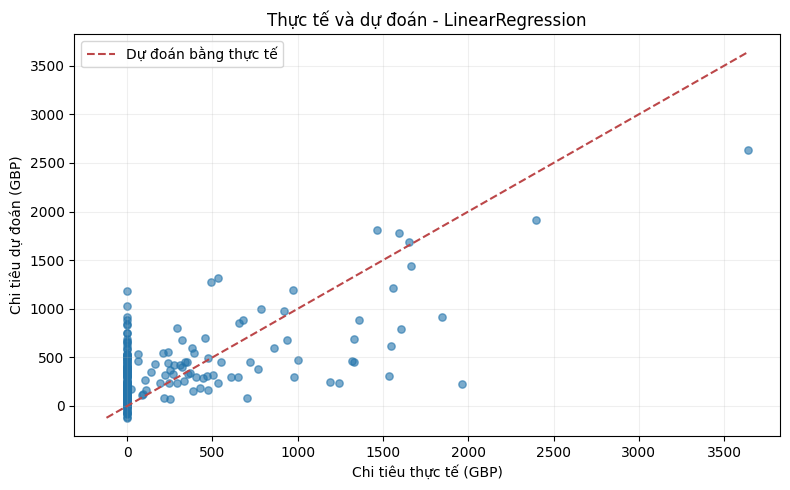

In [68]:
if regression_winner == "LinearRegression":
    best_reg_prediction = pred_linear
else:
    best_reg_prediction = pred_tree

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(y_test_r, best_reg_prediction, alpha=0.6, s=28, color="#2374AB")
minimum = min(float(y_test_r.min()), float(np.min(best_reg_prediction)))
maximum = max(float(y_test_r.max()), float(np.max(best_reg_prediction)))
ax.plot([minimum, maximum], [minimum, maximum], linestyle="--", color="#BC4749",
        label="Dự đoán bằng thực tế")
ax.set_xlabel("Chi tiêu thực tế (GBP)")
ax.set_ylabel("Chi tiêu dự đoán (GBP)")
ax.set_title(f"Thực tế và dự đoán - {regression_winner}")
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "actual_vs_predicted.png", dpi=200, bbox_inches="tight")
if "__file__" not in globals():
    plt.show()
plt.close(fig)

## 8 Xuất kết quả phục vụ báo cáo

Lưu bảng chỉ số, kết quả dự đoán của 200 khách hàng trong tập kiểm tra và ảnh biểu đồ
vào thư mục `ket_qua`. `CustomerID` chỉ được thêm vào kết quả để đối chiếu.

In [69]:
regression_results.to_csv(
    OUTPUT_DIR / "so_sanh_mo_hinh.csv", index=False, encoding="utf-8-sig"
)

test_predictions = pd.DataFrame({
    "Dong_du_lieu": X_test_r.index.to_numpy(),
    "Thuc_te_GBP": y_test_r.to_numpy(),
    "Du_doan_LinearRegression_GBP": pred_linear,
    "Du_doan_DecisionTree_GBP": pred_tree
})
if "CustomerID" in data.columns:
    test_predictions.insert(1, "CustomerID", data.loc[X_test_r.index, "CustomerID"].to_numpy())
test_predictions.to_csv(
    OUTPUT_DIR / "du_doan_tap_test.csv", index=False, encoding="utf-8-sig"
)

best_row = regression_results.loc[regression_results["Model"] == regression_winner].iloc[0]
print(f"Kết luận: {regression_winner} đạt R² = {best_row['R2']:.4f}, "
      f"RMSE = {best_row['RMSE']:.2f} GBP trên {len(y_test_r)} khách hàng kiểm tra.")
print("Đã lưu bảng chỉ số, dự đoán và biểu đồ vào:", OUTPUT_DIR)

Kết luận: LinearRegression đạt R² = 0.3792, RMSE = 414.55 GBP trên 200 khách hàng kiểm tra.
Đã lưu bảng chỉ số, dự đoán và biểu đồ vào: c:\Users\tai33\Desktop\Project_Team_9-main (1)\Project_Team_9-main\notebooks\ket_qua


## Gợi ý nhận xét trong báo cáo

Trình bày mục tiêu, dữ liệu, cách chia tập, cách huấn luyện, bảng chỉ số và biểu đồ.
Giải thích mô hình nào tốt hơn **trong lần đánh giá này**, đồng thời nêu sai số còn lại.
Nếu tiếp tục tinh chỉnh mô hình, nên dùng validation hoặc cross-validation trên tập huấn luyện
và dành tập kiểm tra riêng cho đánh giá cuối cùng.

In [70]:
regression_summary = regression_results.copy()
regression_predictions_saved = test_predictions.copy()

# STAGE 2 — Classification

Các cell tiếp theo lấy từ `Classification.ipynb`.

# TASK 4: DỰ ĐOÁN KHÁCH CÓ MUA LẠI TRONG 90 NGÀY HAY KHÔNG

**Bài toán:** với mỗi khách đã từng mua hàng, mô hình đoán xem khách đó **có mua lại trong 90 ngày tới hay không**.

- **Đáp án cần dự đoán:** cột `Mua_lai_90_ngay`, trong đó **1** là có mua lại và **0** là không mua lại.
- **Dữ liệu:** `data_khach_hang.csv` (1.000 khách, mỗi khách một dòng, đã chuẩn bị ở Stage 1).



## Bước 1. Nạp thư viện và đọc dữ liệu

In [71]:
# --- Thư viện xử lý dữ liệu và vẽ biểu đồ ---
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Thư viện học máy (scikit-learn) ---
from sklearn.model_selection import train_test_split    # chia dữ liệu thành train / test
from sklearn.preprocessing import StandardScaler        # đưa các cột về cùng thang đo
from sklearn.linear_model import LogisticRegression     # mô hình 1
from sklearn.tree import DecisionTreeClassifier         # mô hình 2
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_score, recall_score, f1_score)

import joblib   # dùng để lưu mô hình ở bước cuối

from pathlib import Path

# Tìm thư mục dự án khi mở từ thư mục gốc hoặc notebooks.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'Data').is_dir() and (p / 'notebooks').is_dir())
df = pd.read_csv(ROOT / 'Data/processed/data_khach_hang.csv')
df.head()

,CustomerID,Frequency,MonetaryGBP,TotalUnits,AvgProductsPerInvoice,Country,Kenh_lien_he_mo_phong,RecencyDays,ObservedTenureDays,AvgOrderValueGBP,Chi_tieu_90_ngay_GBP,Mua_lai_90_ngay,RegionGroup
0,12354,1,1079.40,530,58.000000,Spain,Email,132,132,1079.400000,0.00,0,Other countries
1,12358,3,1774.04,622,17.333333,Austria,Phone,50,450,591.346667,0.00,0,Other countries
2,12363,2,552.00,408,11.500000,Unspecified,SMS,9,142,276.000000,0.00,0,Other countries
3,12365,2,641.38,174,11.000000,Cyprus,SMS,191,191,320.690000,0.00,0,Other countries
4,12370,5,3018.07,2053,29.600000,Cyprus,SMS,174,524,603.614000,739.28,1,Other countries


## Bước 2. Chọn dữ liệu đầu vào (X) và đáp án (y)

**X** gồm 7 cột mô tả hành vi mua hàng của khách **trước ngày 01/09/2011**:

| Cột | Ý nghĩa |
|---|---|
| `RecencyDays` | Số ngày từ lần mua gần nhất đến ngày 01/09/2011 |
| `Frequency` | Số hóa đơn đã mua |
| `MonetaryGBP` | Tổng tiền đã chi (bảng Anh) |
| `TotalUnits` | Tổng số sản phẩm đã mua |
| `AvgProductsPerInvoice` | Số mã sản phẩm khác nhau trung bình trên mỗi hóa đơn |
| `ObservedTenureDays` | Số ngày từ lần mua đầu tiên đến ngày 01/09/2011 |
| `AvgOrderValueGBP` | Giá trị trung bình mỗi hóa đơn (`MonetaryGBP` chia `Frequency`) |

**Không đưa vào X:**
- `Chi_tieu_90_ngay_GBP`: là số tiền khách chi *sau* ngày 01/09/2011. Nếu đưa vào thì mô hình "biết trước đáp án" (khách có chi tiêu lớn hơn 0 thì chắc chắn đã mua lại).
- `CustomerID` (chỉ là mã khách), `Kenh_lien_he_mo_phong` (dữ liệu mô phỏng), `Country` và `RegionGroup` .

In [72]:
# Các cột dùng để dự đoán
features = ['RecencyDays', 'Frequency', 'MonetaryGBP', 'TotalUnits',
            'AvgProductsPerInvoice', 'ObservedTenureDays', 'AvgOrderValueGBP']

X = df[features]               # dữ liệu đầu vào
y = df['Mua_lai_90_ngay']      # đáp án: 1 = mua lại, 0 = không mua lại

print('Số khách:', len(df))
print('Số cột đầu vào:', len(features))

Số khách: 1000
Số cột đầu vào: 7


## Bước 3. Kiểm tra số khách mua lại và không mua lại có chênh nhau nhiều không
Nếu một nhóm quá ít khách, mô hình dễ bỏ qua nhóm đó. Vì vậy cần đếm trước.

In [73]:
print('Số khách theo từng nhóm (0 = không mua lại, 1 = mua lại):')
print(y.value_counts())
print()
print('Tỷ lệ (%):')
print((y.value_counts(normalize=True) * 100).round(1))

Số khách theo từng nhóm (0 = không mua lại, 1 = mua lại):
Mua_lai_90_ngay
0    557
1    443
Name: count, dtype: int64

Tỷ lệ (%):
Mua_lai_90_ngay
0    55.7
1    44.3
Name: proportion, dtype: float64


**Kết quả:** 557 khách không mua lại (55,7%) và 443 khách mua lại (44,3%).

Hai nhóm chênh nhau **không nhiều**, nên không cần nhân bản hay xóa bớt dữ liệu. Ở bước huấn luyện, mình vẫn đặt `class_weight='balanced'` để mô hình coi trọng hai nhóm như nhau.

## Bước 4. Chia dữ liệu: 80% để học (train), 20% để kiểm tra (test)
- Mô hình chỉ được **học** trên tập train. Tập test là "bài kiểm tra" mô hình chưa từng thấy.
- `stratify=y` giúp tỷ lệ mua lại ở train và test giống nhau.
- `random_state=42` giúp mỗi lần chạy ra cùng một kết quả.

In [74]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,        # 20% khách để kiểm tra
    stratify=y,           # giữ tỷ lệ mua lại giống nhau ở hai tập
    random_state=42)

print('Số khách để học (train):', len(X_train))
print('Số khách để kiểm tra (test):', len(X_test))

Số khách để học (train): 800
Số khách để kiểm tra (test): 200


## Bước 5. Đưa các cột về cùng thang đo (chỉ cần cho Logistic Regression)
Các cột có độ lớn rất khác nhau: `MonetaryGBP` có thể lên tới hàng nghìn, còn `Frequency` chỉ vài đơn vị. Logistic Regression cần các cột cùng thang đo, còn cây quyết định thì không cần.

Cách làm đúng là **học** cách chuẩn hóa chỉ từ tập train (`fit_transform`), rồi **áp dụng lại** cho tập test (`transform`). Làm vậy thì tập test không "lộ" thông tin cho mô hình.

In [75]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   # học cách chuẩn hóa từ train, rồi chuẩn hóa train
X_test_scaled = scaler.transform(X_test)         # chỉ chuẩn hóa test, không học lại

## Bước 6. Huấn luyện 2 mô hình
- **Logistic Regression:** tính ra xác suất khách sẽ mua lại từ các cột đầu vào.
- **Decision Tree (cây quyết định):** hỏi liên tiếp các câu dạng "nếu... thì...". Giới hạn cây **tối đa 3 tầng** (`max_depth=3`) để cây không học thuộc dữ liệu.

In [76]:
# Mô hình 1: Logistic Regression (học trên dữ liệu đã chuẩn hóa)
logistic = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
logistic.fit(X_train_scaled, y_train)

# Mô hình 2: Decision Tree, tối đa 3 tầng (học trên dữ liệu gốc)
tree = DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=42)
tree.fit(X_train, y_train)

print('Đã huấn luyện xong 2 mô hình.')

Đã huấn luyện xong 2 mô hình.


**Thử xem điều gì xảy ra nếu không giới hạn số tầng của cây:**

In [77]:
tree_khong_gioi_han = DecisionTreeClassifier(class_weight='balanced', random_state=42)
tree_khong_gioi_han.fit(X_train, y_train)

print('Cây không giới hạn - độ chính xác trên train:', round(tree_khong_gioi_han.score(X_train, y_train), 3))
print('Cây không giới hạn - độ chính xác trên test :', round(tree_khong_gioi_han.score(X_test, y_test), 3))

Cây không giới hạn - độ chính xác trên train: 1.0


Cây không giới hạn - độ chính xác trên test : 0.595


**Kết quả:** cây không giới hạn đúng 100% trên train nhưng chỉ khoảng 59,5% trên test. Nghĩa là cây đã **học thuộc** dữ liệu cũ chứ không học được quy luật. Vì vậy mô hình cây dùng ở các bước sau là cây giới hạn 3 tầng.

## Bước 7. Dự đoán trên tập test và in báo cáo
Cách đọc báo cáo (với nhóm **Mua lại**):
- **Precision:** trong số khách mô hình báo "sẽ mua lại", bao nhiêu phần trăm là đúng.
- **Recall:** trong số khách thật sự mua lại, mô hình tìm ra được bao nhiêu phần trăm.
- **F1:** điểm tổng hợp của Precision và Recall (càng cao càng tốt).
- **Accuracy:** tỷ lệ dự đoán đúng trên tất cả khách.

In [78]:
pred_logistic = logistic.predict(X_test_scaled)   # dự đoán của Logistic Regression
pred_tree = tree.predict(X_test)                  # dự đoán của Decision Tree

class_names = ['Không mua lại', 'Mua lại']

print('===== Logistic Regression =====')
print(classification_report(y_test, pred_logistic, target_names=class_names))

print('===== Decision Tree =====')
print(classification_report(y_test, pred_tree, target_names=class_names))

===== Logistic Regression =====
               precision    recall  f1-score   support

Không mua lại       0.78      0.78      0.78       111
      Mua lại       0.73      0.73      0.73        89

     accuracy                           0.76       200
    macro avg       0.76      0.76      0.76       200
 weighted avg       0.76      0.76      0.76       200

===== Decision Tree =====
               precision    recall  f1-score   support

Không mua lại       0.76      0.66      0.71       111
      Mua lại       0.63      0.74      0.68        89

     accuracy                           0.69       200
    macro avg       0.70      0.70      0.69       200
 weighted avg       0.70      0.69      0.70       200



## Bước 8. Confusion matrix (bảng đếm dự đoán đúng và sai)
Mỗi ô là số khách. **Hàng** là thực tế, **cột** là dự đoán.
- Đường chéo (trên trái và dưới phải) là các dự đoán **đúng**.
- Hai ô còn lại là các dự đoán **sai**.

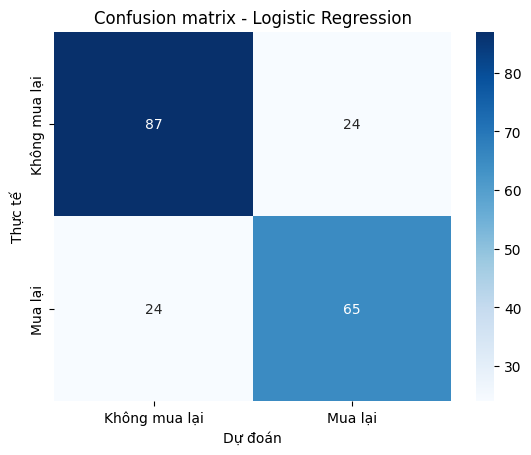

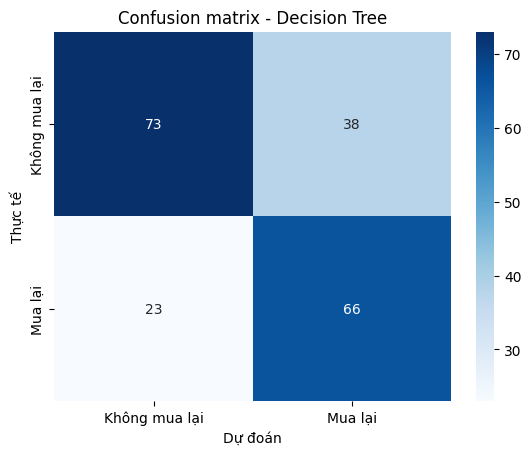

In [79]:
def plot_confusion(y_true, y_pred, title):
    matrix = confusion_matrix(y_true, y_pred)
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(title)
    plt.xlabel('Dự đoán')
    plt.ylabel('Thực tế')
    plt.show()

plot_confusion(y_test, pred_logistic, 'Confusion matrix - Logistic Regression')
plot_confusion(y_test, pred_tree, 'Confusion matrix - Decision Tree')

## Bước 9. So sánh hai mô hình

In [80]:
def get_scores(y_true, y_pred):
    return [accuracy_score(y_true, y_pred),
            precision_score(y_true, y_pred),    # tính cho nhóm Mua lại
            recall_score(y_true, y_pred),
            f1_score(y_true, y_pred)]

bang_so_sanh = pd.DataFrame(
    {'Logistic Regression': get_scores(y_test, pred_logistic),
     'Decision Tree': get_scores(y_test, pred_tree)},
    index=['Accuracy', 'Precision (mua lại)', 'Recall (mua lại)', 'F1 (mua lại)'])

bang_so_sanh.round(3)

,Logistic Regression,Decision Tree
Accuracy,0.76,0.695
Precision (mua lại),0.73,0.635
Recall (mua lại),0.73,0.742
F1 (mua lại),0.73,0.684


**Kết luận:** trong lần chia này, **Logistic Regression tốt hơn** vì cao hơn ở Accuracy, Precision và F1. Decision Tree chỉ nhỉnh hơn ở Recall: cây tìm ra nhiều khách mua lại hơn nhưng cũng báo nhầm nhiều hơn.



## Bước 10. Lưu mô hình để dùng cho giao diện (Task 5)
Giao diện cần cả `scaler` và `logistic`, vì Logistic Regression đã học trên dữ liệu được chuẩn hóa.

In [81]:
joblib.dump({'scaler': scaler,
             'logistic': logistic,
             'tree': tree,
             'features': features},
            ROOT / 'models' / 'Classification.joblib')

print('Đã lưu models/Classification.joblib')

Đã lưu models/Classification.joblib


In [82]:
classification_summary = bang_so_sanh.copy()

# STAGE 2 — TASK 5: GIAO DIỆN STREAMLIT

Giao diện gốc nằm tại `app/AI.py`, đi kèm gói đầy đủ. Đã nối dữ liệu và PCA theo kết quả notebook tổng. Cell dưới kiểm tra đủ tệp và in lệnh mở UI. Chạy lệnh đó ở terminal; không khởi chạy server chặn Run All.

**Ảnh chụp UI cho báo cáo:** chạy UI, nhập dữ liệu, nhấn Phân cụm và Dự đoán, chụp các tab thực tế. Notebook không tự tạo ảnh giả thay cho giao diện. Báo cáo/slide vẫn cần đính kèm ảnh chụp và diễn giải theo yêu cầu cô.

In [83]:
required_ui = ['app/AI.py', 'app/data_khach_hang.csv', 'app/kmeans_pca.pkl',
               'app/comparison.csv', 'app/cluster_profile.csv', 'models/PCA.joblib',
               'models/Classification.joblib']
for file in required_ui:
    if not (ROOT / file).exists():
        raise FileNotFoundError(file)
print('Đủ tệp chạy giao diện.')
print('Mở terminal tại:', ROOT)
print('python -m streamlit run app/AI.py')


Đủ tệp chạy giao diện.
Mở terminal tại: c:\Users\tai33\Desktop\Project_Team_9-main (1)\Project_Team_9-main
python -m streamlit run app/AI.py
